In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from typing import Dict, List, Tuple, Optional
import h5py
from utils import load_real_mmf_data
import matplotlib.pyplot as plt
from tqdm import tqdm
from mode_solver import find_guided_modes
from tm_sampler import sample_tm_perturbed_mmf
from utils import (
    plot_results as utils_plot_results,
    plot_training_intensity_example as utils_plot_training_intensity_example,
    plot_training_history as utils_plot_training_history,
    ZoomFFT2D_Optimizable,
    ZernikeAberrationLayer
)
from metrics_losses import (
    calculate_phase_aligned_frobenius_norm,
    calculate_phase_aligned_tm_error,
    evaluate_reconstruction as metrics_evaluate_reconstruction
)


In [2]:
from TM_retrieve import TMMeasurementSystem
from metrics_losses import PearsonCorrelationLoss
def optimize_tm_slm(
    tm_system: TMMeasurementSystem,
    slm_patterns: torch.Tensor,
    intensity_targets: torch.Tensor,
    num_epochs: int = 100,
    learning_rate: float = 0.01,
    batch_size: int = 32,
    planes: str = 'both',
    optimize_aberrations: bool = True,
    test_data: Optional[Dict] = None,
    use_exposure_normalization: bool = False
) -> Dict:
    """
    Optimize TM and Aberrations using Adam optimizer.
    
    Uses the TMMeasurementSystem's internal nn.Parameters directly:
    - optimized_tm: Transmission matrix
    - zernike_*: Zernike aberration coefficients (4 sets)
    - zoomfft_*_params: ZoomFFT parameters (3 sets)
    - slm_complex_amplitude: Complex amplitude at SLM plane
    
    Args:
        tm_system: TMMeasurementSystem nn.Module with learnable parameters
        slm_patterns: SLM phase patterns (N, H, W)
        intensity_targets: Target intensities (N, 2, H, W) where [:, 0] = image, [:, 1] = fourier
        num_epochs: Number of training epochs
        learning_rate: Learning rate for Adam optimizer
        batch_size: Batch size for training
        planes: 'both', 'image', or 'fourier' - which plane(s) to optimize on
        optimize_aberrations: If True, optimize aberrations (ZoomFFT and Zernike parameters)
        test_data: Optional dict with test data to evaluate test loss after each epoch
        use_exposure_normalization: If True, apply exposure time normalization (for real lab data).
                                   Calculates optimal scalar a = sum(I_hat * I) / sum(I_hat^2) 
                                   separately for each plane. Set to False for simulated data.
    
    Returns:
        Dict containing optimization history
    """
    print(f"Starting Adam Optimization using TMMeasurementSystem internal parameters.")
    print(f"Optimize Aberrations: {optimize_aberrations}")
    
    # --- 1. Configure which parameters to optimize ---
    # TM is always optimized (use _optimized_tm_param, not the property)
    tm_system._optimized_tm_param.requires_grad_(True)
    tm_system.slm_complex_amplitude.requires_grad_(True)
    
    # Aberration parameters are controlled by the flag
    for param in [tm_system.zernike_before_ft, tm_system.zernike_after_ft,
                  tm_system.zernike_image_plane, tm_system.zernike_fourier_domain]:
        param.requires_grad_(optimize_aberrations)
    
    for param_dict in [tm_system.zoomfft_slm_params, tm_system.zoomfft_out_fwd_params,
                       tm_system.zoomfft_out_inv_params]:
        for param in param_dict.values():
            param.requires_grad_(optimize_aberrations)

    # --- 2. Setup Optimizer using module's parameters ---
    def _is_aberration(name):
        return ('zernike' in name or
                'zoomfft' in name or
                name in ('theta_before_slm', 'theta_after_slm'))

    aberration_params = [
        p for n, p in tm_system.named_parameters()
        if p.requires_grad and _is_aberration(n)
    ]
    # Separate out slm_complex_amplitude for its own lr
    slm_complex_params = [
        p for n, p in tm_system.named_parameters()
        if p.requires_grad and n == 'slm_complex_amplitude'
    ]
    other_params = [
        p for n, p in tm_system.named_parameters()
        if p.requires_grad and not _is_aberration(n) and n != 'slm_complex_amplitude'
    ]

    optimizer = optim.Adam([
        {'params': other_params, 'lr': learning_rate},
        {'params': aberration_params, 'lr': learning_rate / 50},
        {'params': slm_complex_params, 'lr': learning_rate /2},
    ])
    num_trainable_params = sum(p.numel() for p in tm_system.parameters() if p.requires_grad)
    print(f"Number of parameters to be optimized: {num_trainable_params}")
    criterion = nn.MSELoss()
    criterion = PearsonCorrelationLoss(dim=(0,2,3), center=True)
    # Ensure planes is a string (defensive check)
    if not isinstance(planes, str):
        raise TypeError(f"planes must be a string, got {type(planes)}: {planes}")
    planes_l = planes.lower()
    num_measurements = slm_patterns.shape[0]
    num_batches = (num_measurements + batch_size - 1) // batch_size
    history = {
        'epoch_losses': [],
        'test_losses': [],
        'tm_error': [],
        'tm_norm': [],
        'tm_frobenius_error_aligned': []
    }

    print(f"Measurements: {num_measurements} | Batches/Epoch: {num_batches} | LR: {learning_rate}")

    # --- 3. Training Loop ---
    if not isinstance(num_epochs, int):
        num_epochs = int(num_epochs)

    X_list = []
    with torch.no_grad():
        for i in range(num_batches):
            start = i * batch_size
            end = min(start + batch_size, num_measurements)
            batch_slm = slm_patterns[start:end]
            # Get input modes (X)
            batch_X = tm_system.slm_to_input_modes(batch_slm, use_internal_params=True)
            X_list.append(batch_X)
        X_full = torch.cat(X_list, dim=1)
    Pre_epochs = 0
    # Use LBFGS optimizer for Pre-epochs phase
    lbfgs_optimizer = torch.optim.LBFGS(
        optimizer.param_groups[0]['params'],
        lr=1.0,  # You may tune this as appropriate
        max_iter=5,
        history_size=10,
        line_search_fn="strong_wolfe"
    )

    def closure():
        lbfgs_optimizer.zero_grad()
        total_loss = torch.tensor(0.0, device=tm_system.device)   # keep as tensor
        total_samples = 0
        lbfgs_batch_size = 2048
        lbfgs_num_batches = (num_measurements + lbfgs_batch_size - 1) // lbfgs_batch_size
        for j in range(lbfgs_num_batches):
            start = j * lbfgs_batch_size
            end = min(start + lbfgs_batch_size, num_measurements)
            batch_X = X_full[:, start:end]
            batch_Y = tm_system.input_modes_to_output_modes(batch_X)
            batch_I = tm_system.output_modes_to_intensities(batch_Y, use_internal_params=False)
            loss = criterion(batch_I, intensity_targets[start:end])
            batch_n = end - start
            total_samples += batch_n
            total_loss += loss * batch_n
        total_loss /= float(total_samples)
        total_loss.backward()
        return total_loss  # Return final batch's loss for LBFGS

    for i in range(Pre_epochs):
        lbfgs_optimizer.step(closure)
    
    for epoch in range(num_epochs):
        total_epoch_loss = 0.0

        # Shuffle data
        indices = torch.randperm(num_measurements)

        # Loop over batches
        for i in range(num_batches):
            optimizer.zero_grad()
            start = i * batch_size
            end = min(start + batch_size, num_measurements)
            batch_idx = indices[start:end]
            
            # Forward pass using internal parameters (use_internal_params=True by default)
            pred_intensity = tm_system.forward_model_slm(slm_patterns[batch_idx])

            # Exposure time normalization: calculate optimal scalar a = sum(I_hat * I) / sum(I_hat^2)
            if use_exposure_normalization:
                with torch.no_grad():
                    numerator = torch.sum(pred_intensity * intensity_targets[batch_idx], dim=(-1,-2), keepdim=True)
                    denominator = torch.sum(pred_intensity ** 2, dim=(-1,-2), keepdim=True)
                    scale = (numerator / (denominator)).mean(dim=0, keepdim=True).detach()
            else:
                scale = 1.0

            # Apply scale and select planes
            pred_normalized = pred_intensity * scale
            if planes_l == 'image':
                pred_normalized = pred_normalized[:, 0:1]
                target_normalized = intensity_targets[batch_idx][:, 0:1]
            elif planes_l == 'fourier':
                pred_normalized = pred_normalized[:, 1:2]
                target_normalized = intensity_targets[batch_idx][:, 1:2]
            else:
                target_normalized = intensity_targets[batch_idx]
            
            # Print relative power on first batch of each epoch
            if i == 0:
                with torch.no_grad():
                    pred_power = torch.sum(pred_intensity, dim=(-1,-2)).mean(dim=0)
                    rel_power = pred_power[0] / pred_power[1] * (tm_system.dx['im']/tm_system.dx['four'])**2
                print(f"rel_power: {rel_power}")
                
            # Loss (Amplitude)
            # pred_amp = torch.sqrt(pred_normalized)
            # target_amp = torch.sqrt(target_normalized)
            pred_amp, target_amp = pred_normalized, target_normalized
            # Normalization (Crucial for stability)
            norm_factor = torch.mean(target_amp).detach()
            norm_factor = 1.0
            loss = criterion(pred_amp / norm_factor, target_amp / norm_factor)+1e-5*tm_system.slm_complex_amplitude.abs().sum()
            # Backward and step
            loss.backward()
            optimizer.step()
            
            # Track loss for reporting
            total_epoch_loss += loss.item()
        
        # Logging
        avg_loss = total_epoch_loss / num_batches
        
        # Calculate test loss if test data is provided
        test_loss = None
        if test_data is not None:
            with torch.no_grad():
                test_slm = test_data['slm_patterns'].to(tm_system.device)
                test_targets = test_data['intensity_targets'].to(tm_system.device)
                
                # Forward pass using internal parameters
                test_pred = tm_system.forward_model_slm(test_slm)
                
                # Select planes and apply exposure time normalization (if enabled)
                if use_exposure_normalization:
                    if planes_l == 'image':
                        test_pred_sel = test_pred[:, 0:1]
                        test_target_sel = test_targets[:, 0:1]
                        numerator_test = torch.sum(test_pred_sel * test_target_sel)
                        denominator_test = torch.sum(test_pred_sel ** 2)
                        scale_test = (numerator_test / (denominator_test)).detach()
                        test_pred_normalized = test_pred_sel * scale_test
                        test_target_normalized = test_target_sel
                    elif planes_l == 'fourier':
                        test_pred_sel = test_pred[:, 1:2]
                        test_target_sel = test_targets[:, 1:2]
                        numerator_test = torch.sum(test_pred_sel * test_target_sel)
                        denominator_test = torch.sum(test_pred_sel ** 2)
                        scale_test = (numerator_test / (denominator_test)).detach()
                        test_pred_normalized = test_pred_sel * scale_test
                        test_target_normalized = test_target_sel
                    else:
                        # Both planes: calculate scalars separately
                        test_pred_image = test_pred[:, 0:1]
                        test_target_image = test_targets[:, 0:1]
                        numerator_img = torch.sum(test_pred_image * test_target_image)
                        denominator_img = torch.sum(test_pred_image ** 2)
                        scale_img = (numerator_img / (denominator_img)).detach()
                        test_pred_fourier = test_pred[:, 1:2]
                        test_target_fourier = test_targets[:, 1:2]
                        numerator_fourier = torch.sum(test_pred_fourier * test_target_fourier)
                        denominator_fourier = torch.sum(test_pred_fourier ** 2)
                        scale_fourier = (numerator_fourier / (denominator_fourier)).detach()
                        
                        test_pred_normalized = torch.cat([test_pred_image * scale_img, test_pred_fourier * scale_fourier], dim=1)
                        test_target_normalized = test_targets
                else:
                    if planes_l == 'image':
                        test_pred_normalized = test_pred[:, 0:1]
                        test_target_normalized = test_targets[:, 0:1]
                    elif planes_l == 'fourier':
                        test_pred_normalized = test_pred[:, 1:2]
                        test_target_normalized = test_targets[:, 1:2]
                    else:
                        test_pred_normalized = test_pred
                        test_target_normalized = test_targets
                
                # Calculate test loss
                test_pred_amp = torch.sqrt(test_pred_normalized)
                test_target_amp = torch.sqrt(test_target_normalized)
                norm_factor_test = torch.mean(test_target_amp).detach()
                test_loss = criterion(test_pred_amp / norm_factor_test, test_target_amp / norm_factor_test).item()
        
        # Calculate TM metrics
        with torch.no_grad():
            if hasattr(tm_system, 'real_tm_tensor') and tm_system.real_tm_tensor is not None:
                tm_error, _ = calculate_phase_aligned_frobenius_norm(tm_system.real_tm_tensor, tm_system.optimized_tm)
            else:
                tm_error = 0.0
            tm_norm = torch.norm(tm_system.optimized_tm).item()
        
        history['epoch_losses'].append(avg_loss)
        if test_loss is not None:
            history['test_losses'].append(test_loss)
        history['tm_error'].append(tm_error)
        history['tm_norm'].append(tm_norm)
        history['tm_frobenius_error_aligned'].append(tm_error)
        
        # Print losses
        if test_loss is not None:
            print(f"Epoch {epoch+1}/{num_epochs}: Train Loss={avg_loss:.6f}, Test Loss={test_loss:.6f}, TM Norm={tm_norm:.6f}")
        else:
            print(f"Epoch {epoch+1}/{num_epochs}: Loss={avg_loss:.6f}, TM Error={tm_error:.4f}, TM Norm={tm_norm:.6f}")

    print("Optimization Completed.")
    return history

## Alternating Optimization

In [3]:
from tqdm import tqdm

def optimize_tm_alternating_with_aberrations(
    tm_system,
    slm_patterns,
    intensity_targets,
    num_epochs=20,
    inner_steps=1,          # Steps of GD per batch (usually 1 is enough if alternating)
    learning_rate_Y=0.1,    # LR for the mode coefficients (Y_est)
    learning_rate_phys=0.01,# LR for physical parameters (Zernike, FFT, etc.)
    lambda_consistency=0.1, # Weight for ||Y - TX|| constraint
    ridge_alpha=1e-4,       # Regularization for the T solver
    batch_size=512
):
    N_samples = slm_patterns.shape[0]
    N_modes = len(tm_system.guided_modes)
    device = tm_system.device
    num_batches = (N_samples + batch_size - 1) // batch_size
    print(f"Starting Alternating Optimization with Active Aberration Correction...")
    
    # --- 1. Setup Parameters ---
    
    # A. Create a learnable tensor for Output Modes (Y_est)
    # We initialize it with the current best guess: Y = T_init * X_init
    with torch.no_grad():
        # Get initial X using current (un-optimized) input aberrations
        # We process in chunks to save memory during init
        X_init_list = []
        for i in range(num_batches):
            start = i * batch_size
            end = min(start + batch_size, N_samples)
            batch_slm = slm_patterns[start:end]
            # Use internal params (True) to use the current system state
            batch_X = tm_system.slm_to_input_modes(batch_slm, use_internal_params=True)
            X_init_list.append(batch_X.T) # Store as (Batch, Modes)
            
        X_full_init = torch.cat(X_init_list, dim=0) # (Samples, Modes)
        
        # Y = X @ T^T
        Y_init = X_full_init @ tm_system.optimized_tm.T
        
    # Make Y_est a learnable parameter
    Y_est = nn.Parameter(Y_init.detach().clone())
    
    # B. Configure System Parameters for Optimization
    # We want to optimize EVERYTHING (Aberrations, SLM amplitude, etc.) EXCEPT the TM
    tm_system._optimized_tm_param.requires_grad_(False) # Lock TM for GD step
    
    # Collect all other learnable parameters (Zernike, ZoomFFT, etc.)
    phys_params = [p for n, p in tm_system.named_parameters() 
                   if '_optimized_tm_param' not in n and p.requires_grad]
    
    # C. Optimizer
    # Different learning rates for the latent modes (Y) vs physical parameters
    optimizer = optim.Adam([
        {'params': [Y_est], 'lr': learning_rate_Y},
        {'params': phys_params, 'lr': learning_rate_phys}
    ])
    
    criterion_intensity = PearsonCorrelationLoss(dim=(0,2,3), center=True)
    criterion_consistency = ComplexCosineLoss()
    history = {'loss_intensity_train': [], 'loss_intensity_test': [], 'loss_consistency_train': [], 'loss_consistency_test': [], 'tm_error': []}

    # --- 2. Main Alternating Loop ---
    for epoch in range(num_epochs):
        total_loss_I = 0
        total_loss_consist = 0
        indices = torch.randperm(N_samples)
        # === PHASE 1: Gradient Descent (Optimize Y and Physics) ===
        for i in range(num_batches):
            start = i * batch_size
            end = min(start + batch_size, N_samples)
            batch_idx = indices[start:end]
            
            # 1. Prepare Data
            batch_slm = slm_patterns[batch_idx]       # (B, H, W)
            batch_target = intensity_targets[batch_idx] # (B, 2, H, W)
            batch_Y_est = Y_est[batch_idx]            # (B, N_modes) - The parameter we are learning
            
            # 2. Gradient Steps
            for _ in range(inner_steps):
                optimizer.zero_grad()
                
                # --- A. Dynamic Input Calculation (Crucial for learning Input Aberrations) ---
                # We calculate X inside the loop so gradients flow to zernike_before_ft etc.
                batch_X = tm_system.slm_to_input_modes(batch_slm, use_internal_params=True)
                # batch_X shape: (N_modes, B) -> Transpose to (B, N_modes) for consistency
                batch_X = batch_X.T
                
                # --- B. Intensity Loss (Matches Y to Measurement) ---
                # Calculate I from Y_est (using current Output Aberrations)
                # Note: output_modes_to_intensities expects (N_modes, B), so we transpose Y_est
                pred_intensity = tm_system.output_modes_to_intensities(
                    batch_Y_est.T, 
                    use_internal_params=True
                )
                
                # Normalize to match energy scales (prevents exploding gradients)
                # scale_factor = torch.mean(torch.abs(batch_target)) / (torch.mean(torch.abs(pred_intensity)) + 1e-8)
                loss_I = criterion_intensity(pred_intensity, batch_target)
                
                # --- C. Consistency Loss (Matches Y to Physics T) ---
                # We want Y_est approx T @ X
                # T is fixed (no_grad) here. X is dynamic (has grad). Y is dynamic (has grad).
                with torch.no_grad():
                    current_T = tm_system.optimized_tm # (Modes, Modes)
                
                # Predicted Y based on current Physics (X) and current T
                # (B, Modes) @ (Modes, Modes)^T -> (B, Modes)
                Y_from_physics = batch_X @ current_T.T
                
                loss_consist = criterion_consistency(batch_Y_est, Y_from_physics)
                
                # Total Loss
                loss = loss_I + lambda_consistency * loss_consist
                
                loss.backward()
                optimizer.step()
            
            total_loss_I += loss_I.item()/num_batches
            total_loss_consist += loss_consist.item()/num_batches

        # === PHASE 2: Exact Least Squares (Optimize TM) ===
        # Now that Input Aberrations (defining X) and Output Modes (Y) are improved,
        # we snap the TM to the exact mathematical solution for this pair.
        
        with torch.no_grad():
            # 1. Recompute the FULL X matrix using the NEW input aberrations
            #    We must do this because the aberrations changed in Phase 1.
            X_new_list = []
            for i in range(num_batches):
                start = i * batch_size
                end = min(start + batch_size, N_samples)
                batch_slm = slm_patterns[start:end]
                batch_x = tm_system.slm_to_input_modes(batch_slm, use_internal_params=True)
                X_new_list.append(batch_x) # (Modes, Batch)
            
            # Concatenate to (Modes, All_Samples)
            X_full_new = torch.cat(X_new_list, dim=1)
            
            # 2. Get the full Y estimate
            # Y_est is (Samples, Modes) -> Transpose to (Modes, Samples)
            Y_full_new = Y_est.T 
            Y_phys = tm_system.optimized_tm @ X_full_new
            eps = 1e-8
            numer = torch.sum(Y_phys.conj() * Y_full_new, dim=0)            # (Samples,)
            denom = torch.sum(Y_full_new.conj() * Y_full_new, dim=0) + eps  # (Samples,)
            alpha = numer / denom                                           # (Samples,)
            Y_full_aligned = Y_full_new * alpha.unsqueeze(0)
            # Optionally clip magnitudes to avoid huge scalings:
            # mag_clip = 10.0
            # alpha = torch.clamp(alpha, min=1.0/mag_clip, max=mag_clip)
            Y_full_aligned = Y_full_new * alpha.unsqueeze(0)
            # 3. Solve T = Y * X_dagger (Ridge Regression)
            # Uses the Cholesky solver I provided earlier
            new_T = solve_fast_cholesky(Y_full_aligned, X_full_new, alpha=ridge_alpha)
            
            # 4. Update the System
            tm_system.optimized_tm_tensor = new_T*0.3 + tm_system.optimized_tm_tensor*0.7

        
        # Calculate TM error (if ground truth exists)
        tm_err = 0.0
        if hasattr(tm_system, 'real_tm_tensor'):
             # Use the provided metric function
             from metrics_losses import calculate_phase_aligned_frobenius_norm
             tm_err, _ = calculate_phase_aligned_frobenius_norm(tm_system.real_tm_tensor, tm_system.optimized_tm)
        
        history['loss_intensity_train'].append(total_loss_I)
        history['loss_consistency_train'].append(total_loss_consist)
        history['tm_error'].append(tm_err)
        print(f"Epoch {epoch+1}: Loss_I={total_loss_I:.5f}, Loss_consist={total_loss_consist:.5f}, TM Error={tm_err:.5f}")

    return history

def solve_fast_cholesky(Y, X, alpha=1e-4):
    """
    Optimized solver for N=1500 using Cholesky decomposition.
    
    Args:
        Y: (N, M) Complex matrix
        X: (N, M) Complex matrix
        alpha: Regularization factor (adjust based on noise level)
        
    Returns:
        T: (N, N) The transition matrix
    """
    N = Y.shape[0]
    
    # 1. Compute the Gram matrix (Covariance of X)
    # GPU Matmul is extremely fast here.
    # Result is (N, N) regardless of how large M is.
    G = X @ X.mH 
    
    # 2. Add regularization to the diagonal (Ridge)
    # This ensures the matrix is Positive Definite (PD), required for Cholesky.
    # We add alpha * trace_mean to scale it relatively, or just alpha.
    # Scaling relative to the diagonal values is usually more robust:
    diag_mean = torch.mean(torch.diagonal(G).real)
    regularizer = alpha * diag_mean * torch.eye(N, dtype=Y.dtype, device=Y.device)
    
    A = G + regularizer
    
    # 3. Compute the RHS: YX^H
    rhs = Y @ X.mH
    
    # 4. Solve A * T^H = (YX^H)^H -> A * T^H = X Y^H
    # We solve for T^H because standard solve is Ax=B. 
    # Our equation is T (XX^H + reg) = YX^H. 
    # Transposing: (XX^H + reg) T^H = XY^H.
    
    target = rhs.mH # Shape (N, N)
    
    # Cholesky decomposition: A = L L^H
    L = torch.linalg.cholesky(A)
    
    # Solve A * Solution = target
    T_conj = torch.cholesky_solve(target, L)
    
    return T_conj.mH

class ComplexCosineLoss(nn.Module):
    def __init__(self, eps=1e-8):
        super().__init__()
        self.eps = eps
        
    def forward(self, y_pred, y_target):
        """
        Computes 1 - |CosineSimilarity|.
        Invariant to global phase shift and global scaling.
        
        Args:
            y_pred: (Batch, Modes) Complex Tensor
            y_target: (Batch, Modes) Complex Tensor
        """
        # 1. Compute dot product (Hermitian inner product)
        # sum(y_pred * conj(y_target))
        dot_prod = torch.sum(y_pred * y_target.conj(), dim=1)
        
        # 2. Compute magnitudes
        norm_pred = torch.norm(y_pred, dim=1)
        norm_target = torch.norm(y_target, dim=1)
        
        # 3. Compute Cosine Similarity (Complex)
        # We take the ABSOLUTE value of the dot product to ignore global phase
        cosine_sim = torch.abs(dot_prod) / (norm_pred * norm_target + self.eps)
        
        # 4. Loss = 1 - Correlation
        return 1.0 - torch.mean(cosine_sim)

## System parameters
calculating the parameters suiteable to the lab optical setup

In [4]:
magnification = 50.0  # 50x objective
dx_cam = 3.45e-6  # camera pixel size
dx_im = {'tran': dx_cam/magnification, 'ref': dx_cam/magnification}
dx_four = {'tran': dx_cam, 'ref': dx_cam*(250.0/200.0)}
NA = 0.22  # numerical aperture of the MMF
obj_f = 200e-3/magnification  # objective focal length
et_ratio = 120.0/150.0  # exposure time ratio
bs_split = 0.47736  # beam splitter split ratio
margin = 1.1
four_range = margin*NA*obj_f
core_radius = 25e-6  # core radius of the MMF
im_range = margin*core_radius
dx_SLM = 8e-6*(150.0/400.0)  # SLM pixel size after 4F system
N_pix = {}
for side in ['tran', 'ref']:
    N_pix[side] = {}
    N_pix[side]['im'] = round(im_range/dx_im[side])
    N_pix[side]['four'] = round(four_range/dx_four[side])
N_pix['slm'] = 320
dx_final = {}  # pixels size after resize and cropping
for side in ['tran', 'ref']:
    dx_final[side] = {}
    dx_final[side]['im'] = dx_im[side]*N_pix[side]['im']/64.0
    dx_final[side]['four'] = dx_four[side]*N_pix[side]['four']/64.0
    dx_final[side]['slm'] = dx_SLM*N_pix['slm']/64.0
    
tran_im_factor = magnification**2*bs_split/(1-bs_split)*et_ratio
# lab data
h5_file_path = "measurement_sampler_data4.h5"  # Update with your H5 file path
experiment_group = "experiment_0"  # Update with the experiment group name
train_test_ratio = 0.8
train_data, test_data = load_real_mmf_data(
    h5_file_path=h5_file_path,
    experiment_group=experiment_group,
    train_test_split_ratio=train_test_ratio,
    random_seed=42,
    im_factor=tran_im_factor
)

# System parameters
wavelength = 632.8e-9
core_index = 1.457
# NA = 0.2243  # measured NA in the lab
# core_radius = 25.53e-6  # 25.53 micron core radius measured in the lab
cladding_index = np.sqrt(core_index**2 - NA**2)
N_0 = 128
f = 200e-3 # focal length of the lens
mult_factor = {
    'tran': dx_final['tran']['im']**2/(wavelength*obj_f),
    'slm': dx_final['tran']['slm']**2/(wavelength*obj_f)
}

# Define fiber parameters
fiber_params = {
    'a': core_radius,  # 25 micron core radius
    'n1': core_index,  # Core refractive index
    'n0': cladding_index,  # Cladding refractive index
    'wavelength': wavelength  # 632.8 nm wavelength
}

# Define grid parameters
range_im = (N_0/2)*dx_final['tran']['im']
grid_params = {
    'x_range': (-range_im, range_im),
    'y_range': (-range_im, range_im),
    'nx': N_0,
    'ny': N_0
}

# Define ZoomFFT parameters
a_param = {
    'slm': 2*np.pi*dx_final['tran']['slm']*dx_final['tran']['im']/(wavelength*obj_f),
    'tran': 2*np.pi*dx_final['tran']['im']*dx_final['tran']['four']/(wavelength*obj_f)
}

zoomfft_params = {}
for side in ['slm', 'tran']:
    zoomfft_params[side] = {
        'a_init': a_param[side],
        'n0_init': (N_0 - 1) / 2,
        'm0_init': (N_0 - 1) / 2,
        'k0_init': (N_0 - 1) / 2,
        'l0_init': (N_0 - 1) / 2
    }

# Initialize the system
print("Initializing TM Measurement System...")
tm_system = TMMeasurementSystem(
    fiber_params, grid_params, 
    device='cuda', 
    mult_factor=mult_factor,
    zoomfft_params=zoomfft_params,
    zernike_n_modes=8,
    dx=dx_final['tran']
)


Loading data from measurement_sampler_data4.h5, group: experiment_0
Using dataset keys: PhaseMask, transmission_image, transmission_fourier
Loaded data shapes:
  SLM phase masks: (6000, 128, 128), dtype: uint8
  Image intensities: (6000, 128, 128), dtype: uint8
  Fourier intensities: (6000, 128, 128), dtype: uint8
Converting uint8 phase masks to phase values (0-255 -> 0 to 2π*255/256)...
slm_phase max: 6.258641719818115 | slm_phase min: 0.0

Data split:
  Training samples: 4800 (80.0%)
  Test samples: 1200 (20.0%)
Initializing TM Measurement System...
Calculating guided modes...
Fiber V-number: 54.610
Fiber is multi-mode.
Loading mode_fields from mode_fields_9d25c116.pt...
Successfully loaded mode_fields with shape: torch.Size([1, 2, 128, 128, 1508])
Sampling transmission matrices for 1508 modes...
System initialized with 1508 guided modes
Grid size: 128 x 128
Aberration models initialized: ZoomFFT and 8 Zernike modes
Performance optimizations: Pre-flattened mode fields for fast projec

In [5]:
# ===== SLM Pattern Optimization =====
# Set these flags to test different configurations:
simulated_data = False
if simulated_data:
    use_aberrations_in_target = True  # If True, targets have aberrations; if False, no aberrations
    optimize_aberrations = True       # If True, optimize TM+aberrations; if False, optimize TM only

    print("\n" + "="*60)
    print(f"SLM Pattern Optimization Mode")
    print(f"  Target aberrations: {use_aberrations_in_target}")
    print(f"  Optimize aberrations: {optimize_aberrations}")
    print("="*60)

    # Sample SLM measurements
    print("\nSampling SLM measurements...")
    slm_patterns, intensity_measurements = tm_system.sample_measurements_slm(
        num_measurements=4000, use_aberrations=use_aberrations_in_target)

    # Optimize TM (and optionally aberrations)
    print("\nOptimizing transmission matrix...")
    import time
    start_time = time.time()
    history = optimize_tm_slm(
        tm_system=tm_system,
        slm_patterns=slm_patterns,
        intensity_targets=intensity_measurements,
        num_epochs=50,
        learning_rate=0.005,
        batch_size=512,
        planes='both',
        optimize_aberrations=optimize_aberrations,
        use_exposure_normalization=False
    )
    end_time = time.time()
    print(f"Optimization time: {end_time - start_time:.2f} seconds")


In [6]:
if simulated_data:
    # Evaluate results
    print("\nEvaluating reconstruction quality...")
    evaluation_results = tm_system.evaluate_reconstruction()

    # Print results
    print(f"\nReconstruction Results:")
    print(f"TM Frobenius Error (Phase-Aligned, Normalized): {evaluation_results['tm_frobenius_error_aligned_normalized']:.6f}")
    print(f"Optimal Phase: {evaluation_results['optimal_phase_degrees']:.2f}° ({evaluation_results['optimal_phase_radians']:.4f} rad)")
    print(f"Intensity Mean Error (Normalized): {evaluation_results['intensity_mean_error_normalized']:.6f}")

    # Plot training history
    print("\nPlotting training history...")
    tm_system.plot_training_history(history)

    # Plot evaluation results
    print("\nPlotting evaluation results...")
    tm_system.plot_results(evaluation_results)

## Real MMF Data Processing

Load real measurement data from H5 files and optimize TM.


In [7]:
# ===== Real MMF Data Processing =====
# Configuration
h5_file_path = "measurement_sampler_data3.h5"  # Update with your H5 file path
experiment_group = "experiment_1"  # Update with the experiment group name
train_test_ratio = 0.95  # 80% training, 20% testing

# List available experiments (uncomment to see available groups)
# list_h5_experiments(h5_file_path)

# Load real data
print("\n" + "="*60)
print("Loading Real MMF Measurement Data")
print("="*60)
train_data, test_data = load_real_mmf_data(
    h5_file_path=h5_file_path,
    experiment_group=experiment_group,
    train_test_split_ratio=train_test_ratio,
    random_seed=42,
    im_factor=tran_im_factor
)

# Move data to appropriate device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
train_data['slm_patterns'] = train_data['slm_patterns'].to(device)
train_data['intensity_targets'] = train_data['intensity_targets'].to(device)
test_data['slm_patterns'] = test_data['slm_patterns'].to(device)
test_data['intensity_targets'] = test_data['intensity_targets'].to(device)

# Note: Ensure SLM phase patterns are in range [0, 2π]
# If your data is in a different range, normalize it here:
# train_data['slm_patterns'] = (train_data['slm_patterns'] - train_data['slm_patterns'].min()) / (train_data['slm_patterns'].max() - train_data['slm_patterns'].min()) * 2 * np.pi
# test_data['slm_patterns'] = (test_data['slm_patterns'] - test_data['slm_patterns'].min()) / (test_data['slm_patterns'].max() - test_data['slm_patterns'].min()) * 2 * np.pi

print(f"\nData moved to device: {device}")
print(f"Training data shapes:")
print(f"  SLM patterns: {train_data['slm_patterns'].shape}")
print(f"  Intensity targets: {train_data['intensity_targets'].shape}")
print(f"Test data shapes:")
print(f"  SLM patterns: {test_data['slm_patterns'].shape}")
print(f"  Intensity targets: {test_data['intensity_targets'].shape}")
tot_power = torch.sum(train_data['intensity_targets'], dim=(-1,-2)).mean(dim=0)
print(f"Total power: {tot_power[0]/tot_power[1]*(dx_final['tran']['im']/dx_final['tran']['four'])**2}")


Loading Real MMF Measurement Data
Loading data from measurement_sampler_data3.h5, group: experiment_1
Using dataset keys: PhaseMask, transmission_image, transmission_fourier
Loaded data shapes:
  SLM phase masks: (6000, 128, 128), dtype: uint8
  Image intensities: (6000, 128, 128), dtype: uint8
  Fourier intensities: (6000, 128, 128), dtype: uint8
Converting uint8 phase masks to phase values (0-255 -> 0 to 2π*255/256)...
slm_phase max: 6.258641719818115 | slm_phase min: 0.0

Data split:
  Training samples: 5699 (95.0%)
  Test samples: 301 (5.0%)

Data moved to device: cuda
Training data shapes:
  SLM patterns: torch.Size([5699, 128, 128])
  Intensity targets: torch.Size([5699, 2, 128, 128])
Test data shapes:
  SLM patterns: torch.Size([301, 128, 128])
  Intensity targets: torch.Size([301, 2, 128, 128])
Total power: 1.0483437776565552


In [8]:
# Initialize the system
tm_system_real = TMMeasurementSystem(
    fiber_params, grid_params, 
    device='cuda', 
    mult_factor=mult_factor,
    zoomfft_params=zoomfft_params,
    zernike_n_modes=8,
    lab_data=False,
    dx=dx_final['tran'],
    enforce_symmetric_tm=True
)
print("System initialized successfully!")

Calculating guided modes...
Fiber V-number: 54.610
Fiber is multi-mode.
Loading mode_fields from mode_fields_9d25c116.pt...
Successfully loaded mode_fields with shape: torch.Size([1, 2, 128, 128, 1508])
Sampling transmission matrices for 1508 modes...
System initialized with 1508 guided modes
Grid size: 128 x 128
Aberration models initialized: ZoomFFT and 8 Zernike modes
Performance optimizations: Pre-flattened mode fields for fast projection
System initialized successfully!


Scanning 1296 target points...
torch.Size([128, 128])


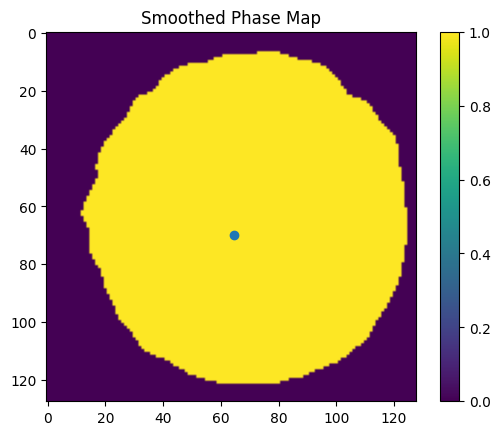

x_0, y_0: 64.48697116813632, 69.81918161101754
x_0_n, y_0_n: 1.015542853041517, 1.0995146710396464


In [9]:
import torch
import torch.nn.functional as F
import numpy as np

def median_filter_pytorch(input_tensor, kernel_size):
    """
    Applies a 2D median filter to a PyTorch tensor (B, C, H, W).

    Args:
        input_tensor (torch.Tensor): Input tensor of shape (B, C, H, W).
        kernel_size (int): Size of the square median filter kernel (e.g., 3 for 3x3).

    Returns:
        torch.Tensor: Filtered tensor.
    """
    if kernel_size % 2 == 0:
        raise ValueError("Kernel size must be odd.")
    
    # Calculate padding to maintain original image size
    padding = kernel_size // 2
    
    # Unfold the input tensor into patches
    # The output shape of unfold is (B, C * kernel_size * kernel_size, H_out * W_out)
    unfolded = F.unfold(input_tensor, kernel_size=kernel_size, padding=padding, stride=1)
    
    # Reshape the unfolded tensor to easily calculate the median along the patch dimension
    # Shape becomes (B, C, kernel_size*kernel_size, H_out*W_out)
    # Then transpose to (B, C, H_out*W_out, kernel_size*kernel_size) to sort along the last dim
    unfolded = unfolded.view(input_tensor.shape[0], input_tensor.shape[1], kernel_size*kernel_size, -1).transpose(2, 3)

    # Calculate the median along the last dimension (the patch values)
    # torch.median returns a named tuple (values, indices), we only need the values
    median_values = torch.median(unfolded, dim=-1)[0]
    
    # Reshape back to the original image dimensions (B, C, H, W)
    output_tensor = median_values.view(input_tensor.shape[0], input_tensor.shape[1], input_tensor.shape[2], input_tensor.shape[3])
    
    return output_tensor

def get_aggregated_active_pupil(slm_phases, intensity_images, grid_step=3, percentile=90):
    """
    Recovers the full active pupil by aggregating correlation maps from multiple output targets.
    
    Args:
        slm_phases: (N, H_slm, W_slm) complex or phase tensor.
        intensity_images: (N, H_cam, W_cam) intensity tensor.
        grid_step: Stride for sampling target points in the output image (smaller = more detailed, slower).
        percentile: The top X% of pixels to keep from each individual map (e.g., 90 for top 10%).
    """
    N, H_slm, W_slm = slm_phases.shape
    _, H_cam, W_cam = intensity_images.shape
    device = slm_phases.device

    # 1. Pre-calculate SLM Phasors (do this once to save time)
    slm_phasors = torch.exp(1j * slm_phases)
    # Centering and Normalizing SLM data once
    phasors_centered = slm_phasors - slm_phasors.mean(dim=0, keepdim=True)
    # Normalizing by std dev is good, but for speed in a loop, simple centering is often enough.
    # If you want strict Pearson correlation, keep the normalization:
    phasors_std = torch.sqrt(torch.mean(torch.abs(phasors_centered)**2, dim=0, keepdim=True))
    phasors_norm = phasors_centered / phasors_std

    # Accumulator for the final map
    master_pupil_map = torch.zeros((H_slm, W_slm), device=device)
    
    # 2. Loop over a grid of target points in the camera image
    # We select points across the fiber face to capture all modes.
    # Assumes the fiber face is roughly centered or fills the frame.
    y_coords = range(10, H_cam - 10, grid_step)
    x_coords = range(10, W_cam - 10, grid_step)
    
    print(f"Scanning {len(y_coords)*len(x_coords)} target points...")

    for y in y_coords:
        for x in x_coords:
            # A. Get Target Signal (Single Pixel or Small ROI)
            # Using a 3x3 ROI averaging reduces camera read noise
            target_signal = intensity_images[:, y-1:y+2, x-1:x+2].mean(dim=(1, 2), keepdim=True)
            
            # Skip dark targets (areas outside the fiber face)
            if target_signal.mean() < intensity_images.mean() * 0.5:
                continue

            # B. Center and Normalize Target
            sig_centered = target_signal - target_signal.mean()
            sig_std = torch.sqrt(torch.mean(sig_centered**2)) + 1e-6
            sig_norm = (sig_centered / sig_std).to(phasors_norm.dtype) # Cast to complex

            # C. Fast Correlation (Matrix Mult)
            # (H*W, N) @ (N, 1) -> (H*W, 1)
            # Reshaping to 2D for fast matmul instead of einsum can be slightly faster in loops
            # But einsum is fine.
            raw_map = torch.einsum('nhw,ncd->hw', phasors_norm.conj(), sig_norm) / N
            raw_map = raw_map.abs()
            # Median filter requires an extra dimension (N=1, C=1, H, W)
            filtered_map = raw_map.unsqueeze(0).unsqueeze(0)
            for i in range(5):
                filtered_map = median_filter_pytorch(filtered_map, 5)
            raw_map = filtered_map.squeeze(0).squeeze(0)

            # D. Dynamic Thresholding (The Key Step)
            # Find the value separating the top (100-percentile)% pixels
            # We flatten to use quantile
            thresh_val = torch.quantile(raw_map.view(-1), percentile / 100.0)
            # Create a binary mask of "active pixels" for this specific mode
            active_mask = (raw_map > thresh_val).float()
            # mean_map = raw_map.mean()
            # std_map = raw_map.std()
            # active_mask = (raw_map > mean_map + 1.0*std_map)
            # E. Accumulate
            # We add the binary mask. Pixels that are active for MANY modes will have high values.
            master_pupil_map += active_mask*raw_map

    return master_pupil_map

import scipy.ndimage

phase_map = get_aggregated_active_pupil(train_data['slm_patterns'], train_data['intensity_targets'][:,1], grid_step=3, percentile=97)

# Smooth the phase_map using a Gaussian filter
phase_map_np = phase_map.detach().cpu().numpy()
smoothed_phase_map = scipy.ndimage.gaussian_filter(phase_map_np, sigma=2)
slm_mask = smoothed_phase_map > 0.24
plt.figure()
plt.imshow(slm_mask)
plt.colorbar()
plt.title("Smoothed Phase Map")
print(phase_map.shape)
slm_mask = slm_mask/np.sum(slm_mask)
x = np.linspace(0, 127, 128)
Y, X = np.meshgrid(x,x)
x_0_slm = np.sum(X*slm_mask)
y_0_slm = np.sum(Y*slm_mask)
plt.scatter(x_0_slm, y_0_slm)
plt.show()
print(f"x_0, y_0: {x_0_slm}, {y_0_slm}")
print(f"x_0_n, y_0_n: {x_0_slm/63.5}, {y_0_slm/63.5}")

In [10]:
# print(train_data['intensity_targets'].shape)
# im_norm = train_data['intensity_targets']/train_data['intensity_targets'].max(dim=-1, keepdim=True)[0].max(dim=-2, keepdim=True)[0]*6
# im_clip = im_norm.clamp(min=0.0, max=1)**2
# im_sum = im_clip.mean(dim=0)
# mask = im_sum > 0.15
# dens = mask/mask.sum(dim=(1,2),keepdim=True)
# x = torch.linspace(0, 127, 128)
# Y, X = torch.meshgrid(x,x)
# x_0 = (X*dens.cpu()).sum(dim=(1,2))
# y_0 = (Y*dens.cpu()).sum(dim=(1,2))
# print(y_0)
# print(x_0)
# mode_0 = tm_system_real.mode_fields[:,:,:,:,0]
# dens = (mode_0.abs()**2).sum(dim=1)
# dens = dens/dens.sum(dim=(-1,-2),keepdim=True)

# E_fourier_from_image = tm_system_real.zoomfft['tran'](mode_0[0], inverse=False, s_l0=x_0[1].item()/63.5, s_k0=y_0[1].item()/63.5)
# dens_fourier = (E_fourier_from_image.abs()**2).sum(dim=0)
# dens_fourier = dens_fourier/dens_fourier.sum()
# x_0_fourier = (X*dens_fourier.cpu()).sum(dim=(-1,-2))
# y_0_fourier = (Y*dens_fourier.cpu()).sum(dim=(-1,-2))
# print(f"x_0_fourier: {x_0_fourier}, original: {x_0[1]}")
# print(f"y_0_fourier: {y_0_fourier}, original: {y_0[1]}")
# E_image_from_fourier = tm_system_real.zoomfft['tran'](mode_0[1], inverse=True, s_n0=y_0[0].item()/63.5, s_m0=x_0[0].item()/63.5)
# dens_image = (E_image_from_fourier.abs()**2).sum(dim=0)
# dens_image = dens_image/dens_image.sum()
# x_0_image = (X*dens_image.cpu()).sum(dim=(-1,-2))
# y_0_image = (Y*dens_image.cpu()).sum(dim=(-1,-2))
# print(f"x_0_image: {x_0_image}, original: {x_0[0]}")
# print(f"y_0_image: {y_0_image}, original: {y_0[0]}")

In [11]:
# # 1. Define the calculated normalized centers (Values derived from your notebook output)
# # Center = calculated_pixel / 63.5
# print("Applying manual initialization to ZoomFFT parameters...")

# # 2. Update SLM Parameters (Input is SLM)
# # Note: m corresponds to x (columns), n corresponds to y (rows)
# # with torch.no_grad():
# #     tm_system_real.zoomfft_slm_params['s_m0'].fill_(x_0_slm/63.5) # Input X center
# #     tm_system_real.zoomfft_slm_params['s_n0'].fill_(y_0_slm/63.5) # Input Y center

# # 3. Update Output Forward Parameters (Image -> Fourier)
# with torch.no_grad():
#     # Output is Fourier Plane
#     tm_system_real.zoomfft_out_fwd_params['s_l0'].fill_(x_0[1].item()/63.5)
#     tm_system_real.zoomfft_out_fwd_params['s_k0'].fill_(y_0[1].item()/63.5)

# # 4. Update Output Inverse Parameters (Fourier -> Image)
# with torch.no_grad():
#     # Input is Fourier Plane
#     tm_system_real.zoomfft_out_inv_params['s_m0'].fill_(x_0[0].item()/63.5)
#     tm_system_real.zoomfft_out_inv_params['s_n0'].fill_(y_0[0].item()/63.5)
# # with torch.no_grad():
# #     tm_system_real.slm_complex_amplitude.data = torch.tensor(slm_mask, dtype=torch.complex64, device=tm_system_real.slm_complex_amplitude.device)

# print("Initialization complete.")


Optimizing TM on Real MMF Data
Starting Adam Optimization using TMMeasurementSystem internal parameters.
Optimize Aberrations: False
Number of parameters to be optimized: 2293468
Measurements: 5699 | Batches/Epoch: 12 | LR: 0.01
rel_power: 0.999793529510498
Epoch 1/100: Train Loss=0.773608, Test Loss=0.358710, TM Norm=124.640472
rel_power: 0.9999043941497803
Epoch 2/100: Train Loss=0.633857, Test Loss=0.333895, TM Norm=153.746338
rel_power: 0.9999198317527771
Epoch 3/100: Train Loss=0.570269, Test Loss=0.320167, TM Norm=172.911591
rel_power: 0.9999215006828308
Epoch 4/100: Train Loss=0.531373, Test Loss=0.315394, TM Norm=185.987671
rel_power: 0.999919056892395
Epoch 5/100: Train Loss=0.502246, Test Loss=0.313594, TM Norm=195.721405
rel_power: 0.9999153017997742
Epoch 6/100: Train Loss=0.480404, Test Loss=0.312302, TM Norm=203.612717
rel_power: 0.9999100565910339
Epoch 7/100: Train Loss=0.463163, Test Loss=0.311390, TM Norm=210.404053
rel_power: 0.9999074935913086
Epoch 8/100: Train Lo

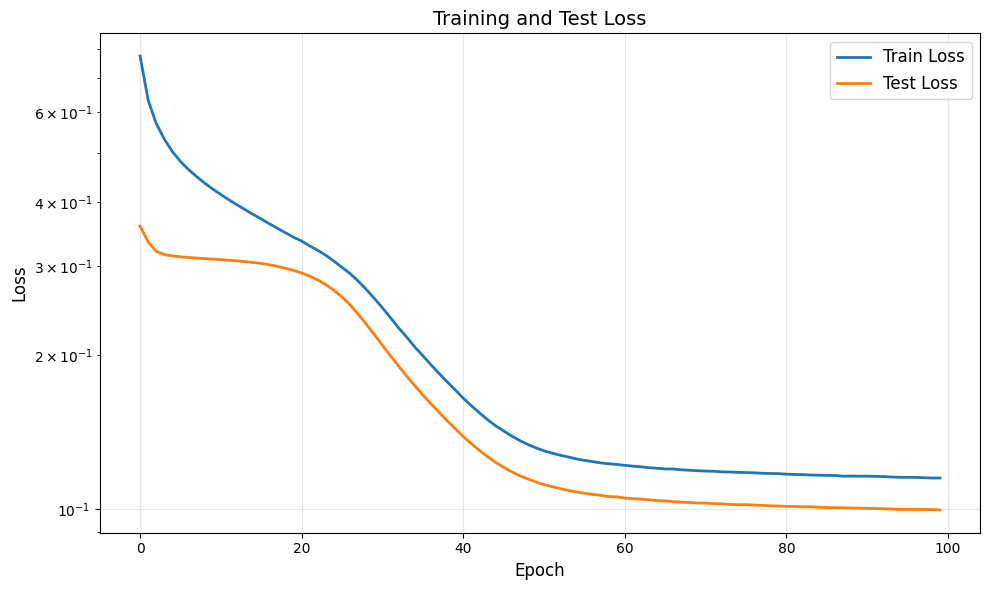


Visualizing Predictions vs Targets


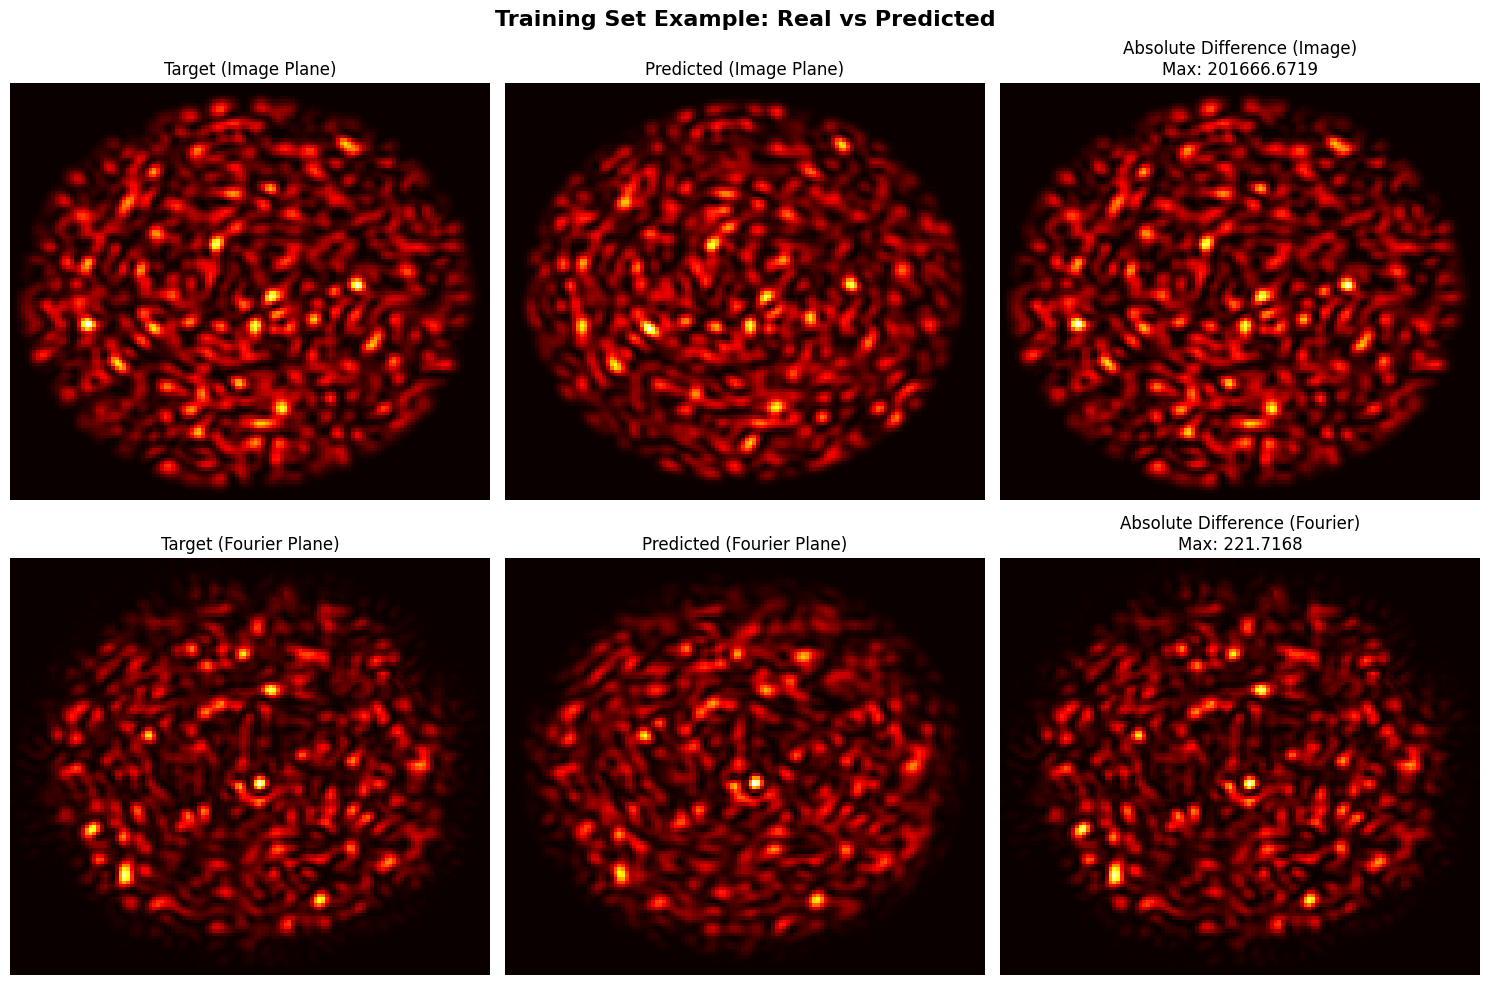

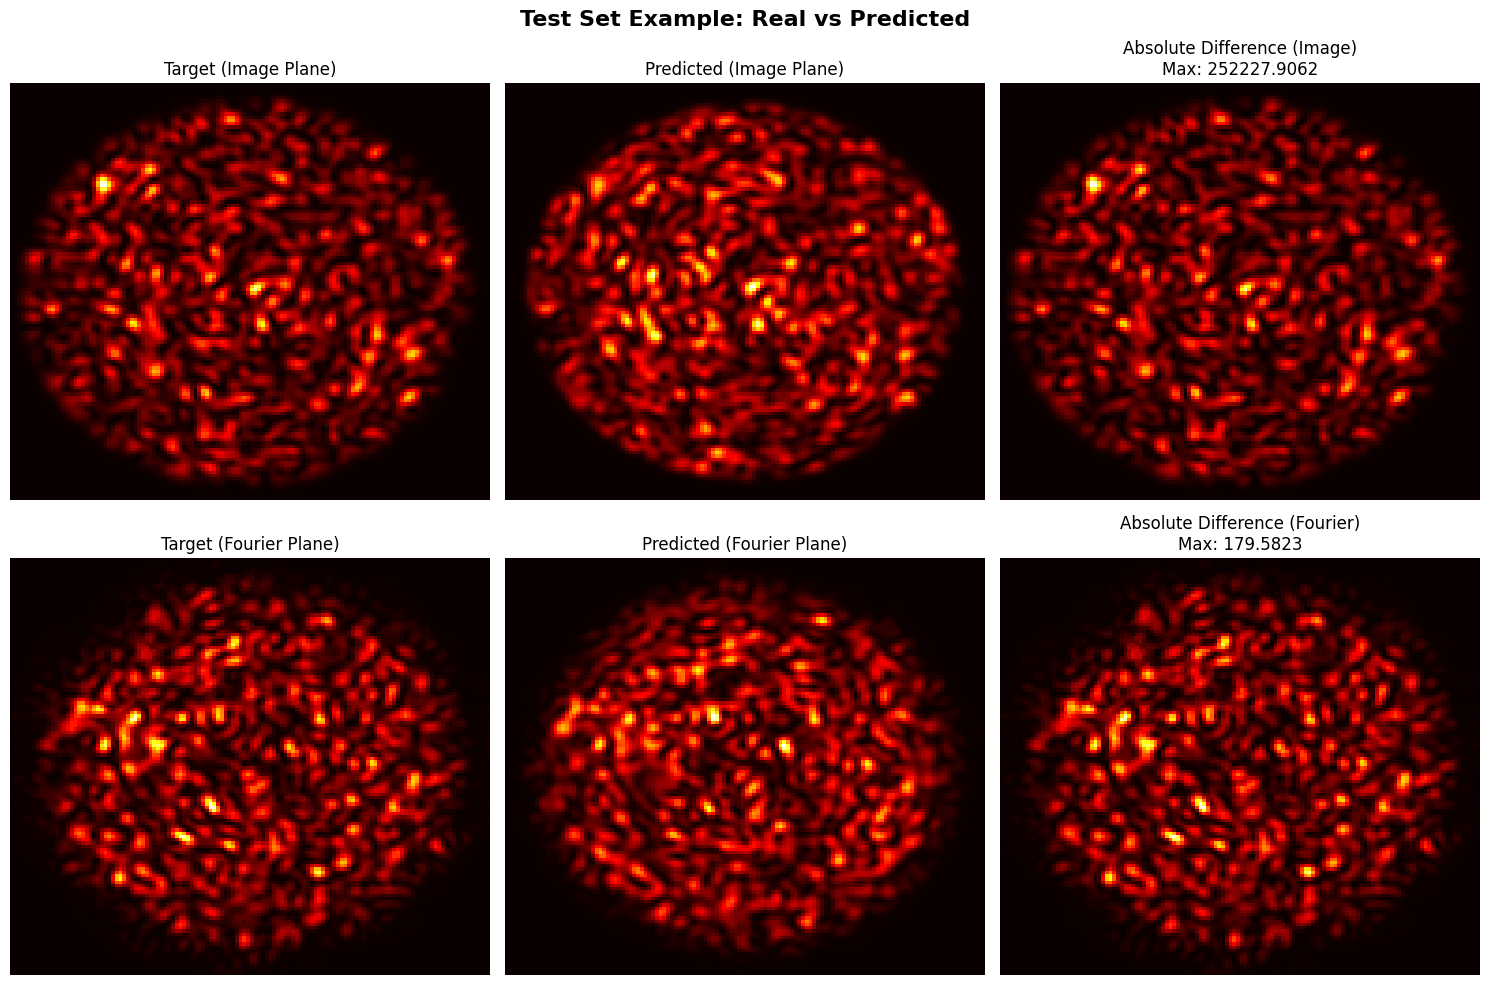

Visualization complete!


In [12]:
from utils import run_spectral_initialization
torch.backends.cuda.matmul.allow_tf32 = True   # faster matmuls on Ampere+
torch.backends.cudnn.benchmark = True
# Optimize TM on real data
beta_modes = np.array([m['beta'] for m in tm_system_real.guided_modes], dtype=np.float64)
optimized_tm_init = np.diag(np.exp(1j * beta_modes)).astype(np.complex64)
tm_system_real.optimized_tm_tensor.data = torch.tensor(optimized_tm_init, dtype=torch.complex64, device=device)
print("\n" + "="*60)
print("Optimizing TM on Real MMF Data")
print("="*60)
# run_spectral_initialization(
#     tm_system=tm_system_real,
#     slm_patterns=train_data['slm_patterns'],
#     intensity_targets=train_data['intensity_targets'],
#     num_iters=10,
#     num_inner_iters=5,
#     ridge_alpha=1e-3
# )
optimize_aberrations = False  # Set to True to optimize aberrations, False for TM only
use_exposure_normalization = False
import time
start_time = time.time()
history_real = optimize_tm_slm(
    tm_system=tm_system_real,
    slm_patterns=train_data['slm_patterns'],
    intensity_targets=train_data['intensity_targets'],
    num_epochs=100,  # Adjust as needed
    learning_rate=0.01,  # Adjust as needed
    batch_size=512,  # Adjust based on your GPU memory
    planes='both',
    optimize_aberrations=optimize_aberrations,
    test_data=test_data,  # Pass test data to track test loss
    use_exposure_normalization=use_exposure_normalization  # Enable exposure time normalization for real lab data
)
# history_real = optimize_tm_alternating_with_aberrations(
#     tm_system=tm_system_real,
#     slm_patterns=train_data['slm_patterns'],
#     intensity_targets=train_data['intensity_targets'],
#     num_epochs=100,
#     inner_steps=1,          # Steps of GD per batch (usually 1 is enough if alternating)
#     learning_rate_Y=1e2,    # LR for the mode coefficients (Y_est)
#     learning_rate_phys=1e-1,# LR for physical parameters (Zernike, FFT, etc.)
#     lambda_consistency=1e0, # Weight for ||Y - TX|| constraint
#     ridge_alpha=1e-1,       # Regularization for the T solver
#     batch_size=128
# )

end_time = time.time()
print(f"\nOptimization completed in {end_time - start_time:.2f} seconds")

# Print final results
print(f"\n{'='*60}")
print("Final Results")
print(f"{'='*60}")
print(f"Final Training Loss: {history_real['epoch_losses'][-1]:.6f}")
if len(history_real['test_losses']) > 0:
    print(f"Final Test Loss: {history_real['test_losses'][-1]:.6f}")
print(f"Final TM Norm: {history_real['tm_norm'][-1]:.6f}")

# Plot training history (including test loss if available)
if len(history_real['test_losses']) > 0:
    plt.figure(figsize=(10, 6))
    plt.plot(history_real['epoch_losses'], label='Train Loss', linewidth=2)
    plt.plot(history_real['test_losses'], label='Test Loss', linewidth=2)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.title('Training and Test Loss', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.yscale('log')
    plt.tight_layout()
    plt.show()
else:
    tm_system_real.plot_training_history(history_real)

# Visualize predictions vs targets for training and test sets
print("\n" + "="*60)
print("Visualizing Predictions vs Targets")
print("="*60)

# Select one example from training set
train_example_idx = 0
train_slm = train_data['slm_patterns'][train_example_idx:train_example_idx+1]
train_target = train_data['intensity_targets'][train_example_idx:train_example_idx+1]

# Generate prediction for training example using internal parameters
train_pred = tm_system_real.forward_model_slm(train_slm)

# Apply exposure normalization if enabled
if use_exposure_normalization:
    # Image plane normalization
    train_pred_img = train_pred[:, 0:1]
    train_target_img = train_target[:, 0:1]
    numerator_img = torch.sum(train_pred_img * train_target_img)
    denominator_img = torch.sum(train_pred_img ** 2)
    scale_img = (numerator_img / (denominator_img + 1e-10)).detach()
    
    # Fourier plane normalization
    train_pred_fourier = train_pred[:, 1:2]
    train_target_fourier = train_target[:, 1:2]
    numerator_fourier = torch.sum(train_pred_fourier * train_target_fourier)
    denominator_fourier = torch.sum(train_pred_fourier ** 2)
    scale_fourier = (numerator_fourier / (denominator_fourier + 1e-10)).detach()
    
    train_pred_normalized = torch.cat([train_pred_img * scale_img, train_pred_fourier * scale_fourier], dim=1)
else:
    train_pred_normalized = train_pred

# Select one example from test set
test_example_idx = 0
test_slm = test_data['slm_patterns'][test_example_idx:test_example_idx+1]
test_target = test_data['intensity_targets'][test_example_idx:test_example_idx+1]

# Generate prediction for test example using internal parameters
test_pred = tm_system_real.forward_model_slm(test_slm)

# Apply exposure normalization if enabled
if use_exposure_normalization:
    # Image plane normalization
    test_pred_img = test_pred[:, 0:1]
    test_target_img = test_target[:, 0:1]
    numerator_img = torch.sum(test_pred_img * test_target_img)
    denominator_img = torch.sum(test_pred_img ** 2)
    scale_img = (numerator_img / (denominator_img + 1e-10)).detach()
    
    # Fourier plane normalization
    test_pred_fourier = test_pred[:, 1:2]
    test_target_fourier = test_target[:, 1:2]
    numerator_fourier = torch.sum(test_pred_fourier * test_target_fourier)
    denominator_fourier = torch.sum(test_pred_fourier ** 2)
    scale_fourier = (numerator_fourier / (denominator_fourier + 1e-10)).detach()
    
    test_pred_normalized = torch.cat([test_pred_img * scale_img, test_pred_fourier * scale_fourier], dim=1)
else:
    test_pred_normalized = test_pred

# Convert to numpy for plotting
train_pred_np = train_pred_normalized[0].detach().cpu().numpy()  # (2, H, W)
train_target_np = train_target[0].detach().cpu().numpy()  # (2, H, W)
test_pred_np = test_pred_normalized[0].detach().cpu().numpy()  # (2, H, W)
test_target_np = test_target[0].detach().cpu().numpy()  # (2, H, W)

# Plot training example
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Training Set Example: Real vs Predicted', fontsize=16, fontweight='bold')

# Image plane
axes[0, 0].imshow(train_target_np[0], cmap='hot', aspect='auto')
axes[0, 0].set_title('Target (Image Plane)', fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(train_pred_np[0], cmap='hot', aspect='auto')
axes[0, 1].set_title('Predicted (Image Plane)', fontsize=12)
axes[0, 1].axis('off')

diff_img = np.abs(train_target_np[0] - train_pred_np[0])
axes[0, 2].imshow(diff_img, cmap='hot', aspect='auto')
axes[0, 2].set_title(f'Absolute Difference (Image)\nMax: {diff_img.max():.4f}', fontsize=12)
axes[0, 2].axis('off')

# Fourier plane
axes[1, 0].imshow(train_target_np[1], cmap='hot', aspect='auto')
axes[1, 0].set_title('Target (Fourier Plane)', fontsize=12)
axes[1, 0].axis('off')

axes[1, 1].imshow(train_pred_np[1], cmap='hot', aspect='auto')
axes[1, 1].set_title('Predicted (Fourier Plane)', fontsize=12)
axes[1, 1].axis('off')

diff_fourier = np.abs(train_target_np[1] - train_pred_np[1])
axes[1, 2].imshow(diff_fourier, cmap='hot', aspect='auto')
axes[1, 2].set_title(f'Absolute Difference (Fourier)\nMax: {diff_fourier.max():.4f}', fontsize=12)
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

# Plot test example
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Test Set Example: Real vs Predicted', fontsize=16, fontweight='bold')

# Image plane
axes[0, 0].imshow(test_target_np[0], cmap='hot', aspect='auto')
axes[0, 0].set_title('Target (Image Plane)', fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(test_pred_np[0], cmap='hot', aspect='auto')
axes[0, 1].set_title('Predicted (Image Plane)', fontsize=12)
axes[0, 1].axis('off')

diff_img = np.abs(test_target_np[0] - test_pred_np[0])
axes[0, 2].imshow(diff_img, cmap='hot', aspect='auto')
axes[0, 2].set_title(f'Absolute Difference (Image)\nMax: {diff_img.max():.4f}', fontsize=12)
axes[0, 2].axis('off')

# Fourier plane
axes[1, 0].imshow(test_target_np[1], cmap='hot', aspect='auto')
axes[1, 0].set_title('Target (Fourier Plane)', fontsize=12)
axes[1, 0].axis('off')

axes[1, 1].imshow(test_pred_np[1], cmap='hot', aspect='auto')
axes[1, 1].set_title('Predicted (Fourier Plane)', fontsize=12)
axes[1, 1].axis('off')

diff_fourier = np.abs(test_target_np[1] - test_pred_np[1])
axes[1, 2].imshow(diff_fourier, cmap='hot', aspect='auto')
axes[1, 2].set_title(f'Absolute Difference (Fourier)\nMax: {diff_fourier.max():.4f}', fontsize=12)
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

print("Visualization complete!")


In [13]:
print(f"before slm: {tm_system_real.theta_before_slm.item()*180/np.pi}")
print(f"after slm: {tm_system_real.theta_after_slm.item()*180/np.pi}")
for item, value in tm_system_real.zoomfft_slm_params.items():
    print(f"{item}: {value.item()}")

before slm: -3.2544954932782195
after slm: 0.0
s_a_x: 1.0
s_a_y: 1.0
s_k0: 1.0
s_l0: 1.0
s_m0: 1.0
s_n0: 1.0


In [14]:
import numpy as np
import cv2

def best_rotation_angle(src, tgt):
    best_angle = 0
    best_score = -np.inf
    h, w = src.shape[:2]
    center = (w // 2, h // 2)

    for angle in range(0, 360):
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(src, M, (w, h))
        # Compute normalized correlation
        corr = np.corrcoef(rotated.ravel(), tgt.ravel())[0, 1]
        if corr > best_score:
            best_score = corr
            best_angle = angle
    return best_angle, best_score
plane = 1
idx = 0
test_pred_np = test_pred_normalized[idx, plane].detach().cpu().numpy()  # (2, H, W)
test_target_np = test_target[idx, plane].detach().cpu().numpy()
best_angle, best_score = best_rotation_angle(test_target_np, test_pred_np)
print(f"Best rotation angle: {best_angle} degrees")
print(f"Best score: {best_score}")


Best rotation angle: 0 degrees
Best score: 0.8629208026083193


(128, 128)


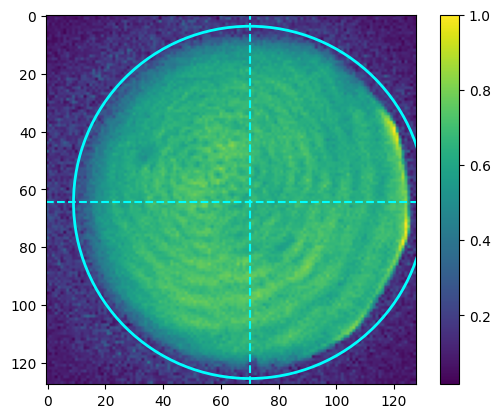

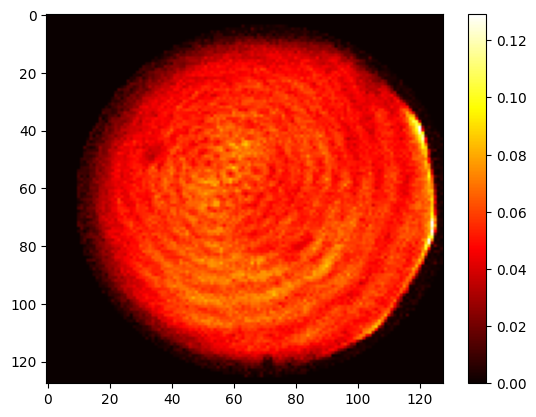

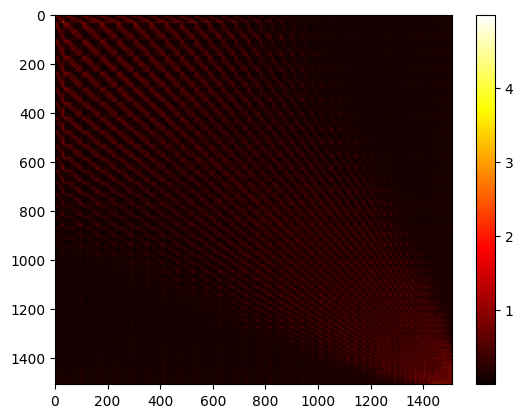

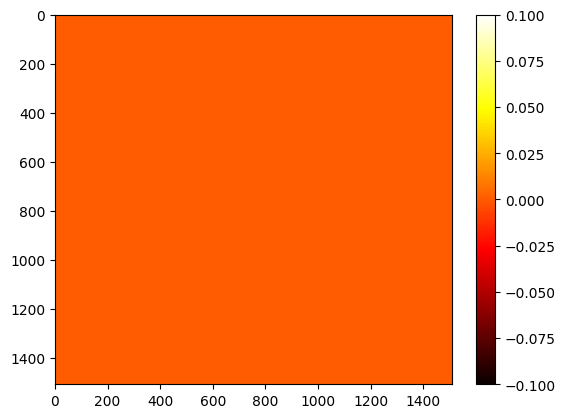

max rel err: 0.0, min rel err: 0.0, avg rel err: 0.0


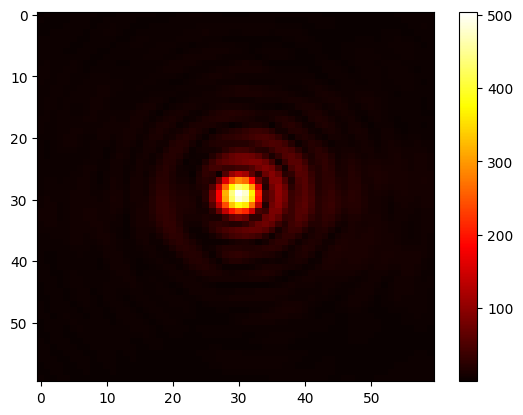

ratio: 0.9847440719604492
max idx: (np.int64(63), np.int64(64))


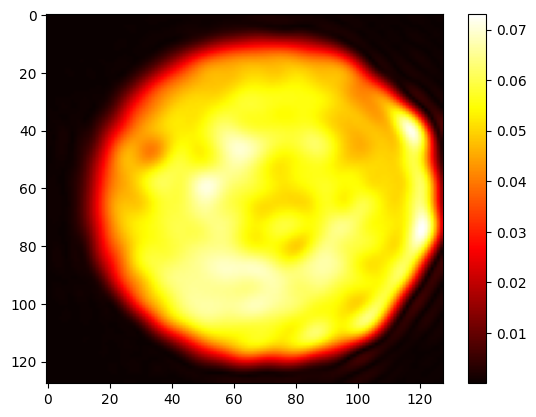

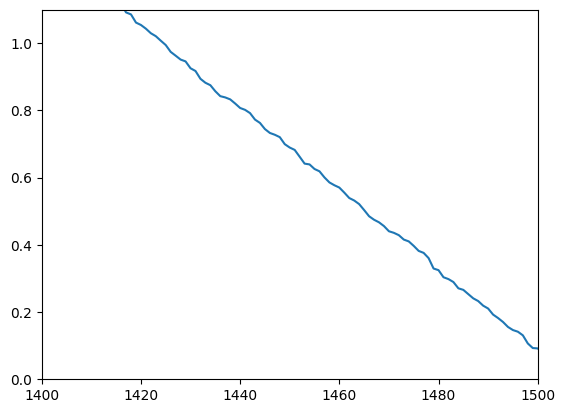

max singular value: 43.13753890991211, min singular value: 0.0038337120786309242, avg singular value: 9.860065460205078
Condition number of the optimized_tm_tensor: 11252.1591796875


In [21]:
amp = tm_system_real.slm_complex_amplitude.detach().cpu().numpy()
print(amp.shape)
plt.figure()
plt.imshow((np.abs(amp)/np.abs(amp).max())**0.5)
import matplotlib.patches as patches

ax = plt.gca()
# Plot a circle with center (69, 64.0) and radius 61
center_x, center_y, radius = 70, 64.5, 61
circle = patches.Circle((center_x, center_y), radius, linewidth=2, edgecolor='cyan', facecolor='none')
ax.add_patch(circle)

# Draw a cross through the center of the circle
ax.axhline(y=center_y, xmin=0, xmax=amp.shape[1], color='cyan', linestyle='--', linewidth=1.5)
ax.axvline(x=center_x, ymin=0, ymax=amp.shape[0], color='cyan', linestyle='--', linewidth=1.5)

plt.colorbar()
plt.show()

amp_clean = np.zeros_like(amp)
yy, xx = np.ogrid[:amp.shape[0], :amp.shape[1]]
center = (center_x, center_y)
radius = radius
mask = (xx - center[0])**2 + (yy - center[1])**2 <= radius**2
amp_clean[mask] = amp[mask]

plt.figure()
plt.imshow(np.abs(amp_clean), cmap='hot', aspect='auto')
plt.colorbar()
plt.show()

TM_abs = tm_system_real.optimized_tm_tensor.abs().detach().cpu().numpy()
plt.figure()
plt.imshow(TM_abs, cmap='hot', aspect='auto')
plt.colorbar()
plt.show()

plt.figure()
plt.imshow(np.abs(TM_abs - TM_abs.T)/(TM_abs+1e-2), cmap='hot', aspect='auto')
plt.colorbar()
plt.show()

rel_err = np.abs(TM_abs - TM_abs.T)#/(TM_abs+1e-2)
print(f"max rel err: {rel_err.max()}, min rel err: {rel_err.min()}, avg rel err: {rel_err.mean()}")

zoomfft_params_slm = tm_system_real._get_zoomfft_params_dict(tm_system_real.zoomfft_slm_params)
zernike_coeffs_before_ft = tm_system_real.zernike_before_ft
E_field_slm = tm_system_real.zernike_layer(torch.tensor(amp_clean, device=tm_system_real.device), zernike_coeffs_before_ft)
E_field_slm_rotated = tm_system_real.zoomfft['slm'](E_field_slm, inverse=False, **zoomfft_params_slm)
E_filt = torch.zeros_like(E_field_slm_rotated)
rad = 30
E_filt[64-rad:64+rad, 64-rad:64+rad] = E_field_slm_rotated[64-rad:64+rad, 64-rad:64+rad]
E_inv = tm_system_real.zoomfft['slm'](E_filt, inverse=True, **zoomfft_params_slm)
E_field_slm_rotated = E_field_slm_rotated.detach().cpu().numpy()

plt.figure()
plt.imshow(np.abs(E_field_slm_rotated[64-rad:64+rad, 64-rad:64+rad]), cmap='hot', aspect='auto')
plt.colorbar()
plt.show()
print(f"ratio: {np.abs(E_field_slm_rotated[64-rad:64+rad, 64-rad:64+rad]**2).sum()/np.abs(E_field_slm_rotated**2).sum()}")
# Find the (x, t) coordinate of the highest absolute value in E_field_slm_rotated
max_idx = np.unravel_index(np.abs(E_field_slm_rotated).argmax(), E_field_slm_rotated.shape)
print(f"max idx: {max_idx}")
plt.figure()
plt.imshow(np.abs(E_inv.detach().cpu().numpy()), cmap='hot', aspect='auto')
plt.colorbar()
plt.show()
# Perform SVD decomposition of the optimized_tm_tensor and print the singular values
u, s, vh = torch.linalg.svd(tm_system_real.optimized_tm_tensor)
plt.figure()
plt.plot(s.detach().cpu().numpy())
plt.ylim(0, 1.1)
plt.xlim(1400,1500)
plt.show()
print(f"max singular value: {s.max().item()}, min singular value: {s.min().item()}, avg singular value: {s.mean().item()}")
# Compute the condition number of the optimized_tm_tensor
condition_number = torch.linalg.cond(tm_system_real.optimized_tm_tensor)
print(f"Condition number of the optimized_tm_tensor: {condition_number.item()}")
# Save mask as uint8 array (1→255, 0→0), flipped around both axes
mask_uint8 = (mask.astype(np.uint8)) * 255
mask_uint8_flipped = np.flip(mask_uint8)
np.save("mask_uint8.npy", mask_uint8_flipped)

# Save absolute value of amplitude, scaled so max is 255, as uint8 array, flipped around both axes
amp_abs = np.abs(amp_clean)
amp_abs_scaled = (amp_abs / amp_abs.max() * 255).clip(0, 255).astype(np.uint8)
amp_abs_scaled_flipped = np.flip(amp_abs_scaled)
np.save("amp_abs_scaled_uint8.npy", amp_abs_scaled_flipped)




Iteration 50/150 | Focus Metric: 691.08
Iteration 100/150 | Focus Metric: 700.60
Iteration 150/150 | Focus Metric: 702.83
Iteration 50/150 | Focus Metric: 694.09
Iteration 100/150 | Focus Metric: 703.77
Iteration 150/150 | Focus Metric: 707.82
Iteration 50/150 | Focus Metric: 692.63
Iteration 100/150 | Focus Metric: 702.70
Iteration 150/150 | Focus Metric: 706.47
Iteration 50/150 | Focus Metric: 695.60
Iteration 100/150 | Focus Metric: 707.56
Iteration 150/150 | Focus Metric: 713.14
Iteration 50/150 | Focus Metric: 691.63
Iteration 100/150 | Focus Metric: 700.53
Iteration 150/150 | Focus Metric: 702.78
[0.8035522699356079, 0.7743375301361084, 0.7330601811408997, 0.7830479145050049, 0.8064994812011719, 0.7078986167907715, 0.8194579482078552, 0.8033069372177124, 0.778323769569397, 0.7747192978858948]


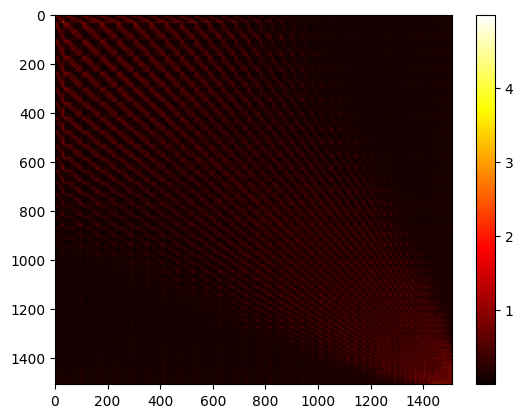

In [16]:
import torch
import torch.nn as nn
import torch.optim as optim
# torch.autograd.set_detect_anomaly(True)

def optimize_slm_pattern_with_tm(
    tm_system, 
    slm_shape=(128, 128),
    num_iterations=100, 
    lr=0.1, 
    center_radius=1,
    target_plane='image'
):
    """
    Optimizes a single SLM phase pattern to maximize the focus metric 
    using a pre-trained TMMeasurementSystem.
    """
    device = tm_system.device
    
    # 1. Freeze all parameters in the TM system to prevent altering the calibrated model
    for param in tm_system.parameters():
        param.requires_grad = False
    tm_system.eval()
    
    # 2. Initialize the SLM phase pattern as a learnable parameter (Batch size = 1)
    slm_phase = nn.Parameter(
        (2 * torch.pi * torch.rand((1, *slm_shape), dtype=torch.float32, device=device))
    )
    optimizer = optim.Adam([slm_phase], lr=lr)
    
    # 3. Retrieve output grid dimensions from the system parameters
    H = tm_system.grid_params['ny']
    W = tm_system.grid_params['nx']
    cy, cx = H // 2, W // 2
    
    # 4. Construct boolean masks for the center and background regions
    center_mask = torch.zeros((H, W), dtype=torch.bool, device=device)
    y_min, y_max = max(0, cy - center_radius), min(H, cy + center_radius + 1)
    x_min, x_max = max(0, cx - center_radius), min(W, cx + center_radius + 1)
    center_mask[y_min:y_max, x_min:x_max] = True
    background_mask = ~center_mask
    
    # Identify the correct plane index (0 for image, 1 for fourier)
    plane_idx = 0 if target_plane.lower() == 'image' else 1
    
    history = []
    
    for i in range(num_iterations):
        optimizer.zero_grad()
        
        # 5. Forward pass through the full calibrated system
        # The system expects the SLM phase pattern directly
        pred_intensity = tm_system.forward_model_slm(slm_phase)
        
        # Extract the 2D intensity map for the target plane
        # pred_intensity shape is (Batch, Planes, H, W)
        plane_intensity = pred_intensity[0, plane_idx]
        
        # 6. Calculate the focus metric
        center_mean = plane_intensity[center_mask].mean()
        background_mean = plane_intensity[background_mask].mean()
        
        focus_metric = center_mean / (background_mean)
        # 7. Minimize the negative metric
        loss = -focus_metric
        
        loss.backward()
        optimizer.step()
        
        history.append(focus_metric.item())
        
        if (i + 1) % 50 == 0:
            print(f"Iteration {i+1}/{num_iterations} | Focus Metric: {focus_metric.item():.2f}")
            
    # Constrain the final phase pattern to physical boundaries [0, 2pi]
    optimized_phase = torch.remainder(slm_phase.detach(), 2 * torch.pi)
    
    return optimized_phase.squeeze(0), history

phases = []
correlations = []
for i in range(5):
    optimized_phase, history = optimize_slm_pattern_with_tm(tm_system_real, 
    slm_shape=(128, 128),
    num_iterations=150, 
    lr=0.1, 
    center_radius=1,
    target_plane='image')
    # Zero mean and unit std normalization
    optimized_phase = torch.exp(1j*optimized_phase)
    normalized_phase = (optimized_phase - optimized_phase.mean()) / optimized_phase.std()
    for j in range(len(phases)):
        corr = torch.mean(phases[j]*normalized_phase.conj())
        correlations.append(corr.abs().item())
    phases.append(normalized_phase)


print(correlations)
TM_abs = tm_system_real.optimized_tm_tensor.abs().detach().cpu().numpy()
plt.figure()
plt.imshow(TM_abs, cmap='hot', aspect='auto')
plt.colorbar()
plt.show()

In [17]:
dx_cam = 3.45e-6
dx_im = {'tran': dx_cam/50.0, 'ref': dx_cam/50.0}
dx_four = {'tran': dx_cam, 'ref': dx_cam*(250.0/200.0)}
four_range = 1.1*0.22*4e-3
im_range = 1.1*25e-6
dx_SLM = 8e-6*(150.0/400.0)
N_pix = {}
for side in ['tran', 'ref']:
    N_pix[side] = {}
    N_pix[side]['im'] = round(im_range/dx_im[side])
    N_pix[side]['four'] = round(four_range/dx_four[side])
N_pix['SLM'] = 320
dx_final_t = {}
c = 0.47736
for side in ['tran', 'ref']:
    dx_final_t[side] = {}
    dx_final_t[side]['im'] = dx_im[side]*N_pix[side]['im']/64.0
    dx_final_t[side]['four'] = dx_four[side]*N_pix[side]['four']/64.0
dx_final_t['SLM'] = dx_SLM*N_pix['SLM']/64.0
a = train_data['intensity_targets'].sum(dim=(2,3))
b = a[:,0]/a[:,1]*(dx_final_t['tran']['im']*50/dx_final_t['tran']['four'])**2*120.0/150.0*c/(1-c)
print(b.mean()-1.0)
print(1/(1+b.mean()))



tensor(1914.3707, device='cuda:0')
tensor(0.0005, device='cuda:0')


## Fit Mode Distributions to Lab Images

Test whether we can fit mode distributions directly to the lab images (bypassing TM optimization).
This helps determine if the issue is with TM optimization or if the images themselves are not fittable.


In [18]:
from tqdm import tqdm
def apply_affine_transform(
    intensity: torch.Tensor,
    scale_x: torch.Tensor,
    scale_y: torch.Tensor,
    translate_x: torch.Tensor,
    translate_y: torch.Tensor,
    rotation: torch.Tensor,
    shear_x: torch.Tensor,
    shear_y: torch.Tensor
) -> torch.Tensor:
    """
    Apply affine transformation to intensity images using PyTorch's built-in functions.
    
    Args:
        intensity: (batch, 1, H, W) intensity images
        scale_x, scale_y: scalar scale factors (same for all images)
        translate_x, translate_y: scalar translation in pixels (same for all images)
        rotation: scalar rotation angle in radians (same for all images)
        shear_x, shear_y: scalar shear factors (same for all images)
        
    Returns:
        Transformed intensity: (batch, 1, H, W)
    """
    import torch.nn.functional as F
    
    batch_size, channels, H, W = intensity.shape
    device = intensity.device
    
    # Normalize coordinates to [-1, 1]
    # Translation needs to be normalized by image size
    translate_x_norm = 2.0 * translate_x / W
    translate_y_norm = 2.0 * translate_y / H
    
    # Build affine transformation matrix (same for all images in batch)
    cos_r = torch.cos(rotation)
    sin_r = torch.sin(rotation)
    
    # Combined transformation: scale * rotation * shear
    sx = scale_x
    sy = scale_y
    shx = shear_x
    shy = shear_y
    
    # Combined: scale * rotation * shear
    a = sx * (cos_r - shx * sin_r)
    b = sx * (sin_r + shx * cos_r)
    c = sy * (shy * cos_r - sin_r)
    d = sy * (shy * sin_r + cos_r)
    
    # Affine matrix: [[a, b, tx], [c, d, ty]]
    # Use torch.stack to preserve gradients (don't use torch.tensor which breaks gradients)
    row1 = torch.stack([a, b, translate_x_norm], dim=0)  # (3,)
    row2 = torch.stack([c, d, translate_y_norm], dim=0)  # (3,)
    theta = torch.stack([row1, row2], dim=0)  # (2, 3)
    
    # Expand to batch size (same transformation for all images)
    theta = theta.unsqueeze(0).expand(batch_size, -1, -1)  # (batch, 2, 3)
    
    # Generate grid and apply transformation
    grid = F.affine_grid(theta, intensity.size(), align_corners=False)
    transformed = F.grid_sample(intensity, grid, mode='bilinear', padding_mode='zeros', align_corners=False)
    
    return transformed


def fit_mode_distributions_to_images(
    tm_system: TMMeasurementSystem = None,
    target_intensities: torch.Tensor = None,
    num_images: int = 10,
    num_epochs: int = 200,
    learning_rate: float = 0.01,
    use_zernike_aberrations: bool = True,
    use_exposure_normalization: bool = True
) -> Dict:
    """
    Fit mode distributions directly to target images with optimizable aberrations.
    
    Calculation flow:
    1. From mode distribution calculate the field at the image plane
    2. Calculate the intensity at the image plane and perform affine transformation
    3. ZoomFFT the field and calculate the intensity at the Fourier plane, perform affine transformation to the intensity
    
    Parameters to optimize:
    1. The mode distributions
    2. Zernike coefficients
    3. The perturbed affine coefficients (for intensity transformations)
    
    Args:
        tm_system: TMMeasurementSystem instance
        target_intensities: Target intensities (N, 2, H, W) where [:, 0] = image, [:, 1] = fourier
        num_images: Number of images to fit (uses first N images)
        num_epochs: Number of optimization epochs
        learning_rate: Learning rate for optimizer
        use_zernike_aberrations: If True, optimize Zernike aberrations
        use_exposure_normalization: If True, apply exposure time normalization
        
    Returns:
        Dict containing optimization history and optimized parameters
    """
    print(f"\n{'='*60}")
    print(f"Fitting Mode Distributions to {num_images} Lab Images")
    print(f"{'='*60}")
    if tm_system is None:
        grid_params = {
            'x_range': (-range_im*2, range_im*2),
            'y_range': (-range_im*2, range_im*2),
            'nx': N_0*2,
            'ny': N_0*2
        }
        zoomfft_params = {}
        for side in ['slm', 'tran']:
            zoomfft_params[side] = {
                'a_init': a_param[side],
                'n0_init': (2*N_0 - 1) / 2,
                'm0_init': (2*N_0 - 1) / 2,
                'k0_init': (2*N_0 - 1) / 2,
                'l0_init': (2*N_0 - 1) / 2
            }
        H = 2*N_0
        tm_system = TMMeasurementSystem(
            fiber_params, grid_params, 
            device='cuda', 
            mult_factor=mult_factor,
            zoomfft_params=zoomfft_params,
            zernike_n_modes=8,
            lab_data=False,
            dx=dx_final['tran']
        )
    else:
        H = target_intensities.shape[2]
    # Use first N images
    target_intensities_subset = target_intensities[:num_images]  # (N, 2, H, W)
    N_modes = tm_system.optimized_tm_tensor.shape[0]
    # 1. Initialize mode distributions (complex values)
    # Shape: (N_modes, num_images)
    mode_dists_real = nn.Parameter(torch.randn(N_modes, num_images, device=tm_system.device) * 0.1)
    mode_dists_imag = nn.Parameter(torch.randn(N_modes, num_images, device=tm_system.device) * 0.1)
    
    # Zernike aberration coefficients (initialized to zero = no aberration)
    if use_zernike_aberrations:
        zernike_image = nn.Parameter(torch.zeros(tm_system.zernike_n_modes, device=tm_system.device))
        zernike_fourier = nn.Parameter(torch.zeros(tm_system.zernike_n_modes, device=tm_system.device))
    else:
        zernike_image = torch.zeros(tm_system.zernike_n_modes, device=tm_system.device)
        zernike_fourier = torch.zeros(tm_system.zernike_n_modes, device=tm_system.device)
    
    # Affine transformation parameters for intensities (same for all images)
    # For each plane: scale_x, scale_y, translate_x, translate_y, rotation, shear_x, shear_y
    # Initialize to identity transformation (scale=1, translate=0, rotation=0, shear=0)
    # Note: If exposure normalization is enabled, it applies global scaling which may make
    # affine scale parameters redundant, but translation/rotation/shear should still be learnable
    affine_img_scale_x = nn.Parameter(torch.tensor(1.0, device=tm_system.device))
    affine_img_scale_y = nn.Parameter(torch.tensor(1.0, device=tm_system.device))
    affine_img_translate_x = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_img_translate_y = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_img_rotation = nn.Parameter(torch.tensor(0.0, device=tm_system.device), requires_grad=False)
    affine_img_shear_x = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_img_shear_y = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    
    affine_fourier_scale_x = nn.Parameter(torch.tensor(1.0, device=tm_system.device))
    affine_fourier_scale_y = nn.Parameter(torch.tensor(1.0, device=tm_system.device))
    affine_fourier_translate_x = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_fourier_translate_y = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_fourier_rotation = nn.Parameter(torch.tensor(0.0, device=tm_system.device), requires_grad=False)
    affine_fourier_shear_x = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    affine_fourier_shear_y = nn.Parameter(torch.tensor(0.0, device=tm_system.device))
    
    im_real_mult = nn.Parameter(torch.ones(H, H, device=tm_system.device))
    im_imag_mult = nn.Parameter(torch.zeros(H, H, device=tm_system.device))
    fourier_real_mult = nn.Parameter(torch.ones(H, H, device=tm_system.device))
    fourier_imag_mult = nn.Parameter(torch.zeros(H, H, device=tm_system.device))
    # Collect all optimizable parameters
    all_params = [mode_dists_real, mode_dists_imag]
    if use_zernike_aberrations:
        all_params += [zernike_image, zernike_fourier]
    all_params += [
        affine_img_scale_x, affine_img_scale_y, affine_img_translate_x, affine_img_translate_y,
        affine_img_rotation, affine_img_shear_x, affine_img_shear_y,
        affine_fourier_scale_x, affine_fourier_scale_y, affine_fourier_translate_x, affine_fourier_translate_y,
        affine_fourier_rotation, affine_fourier_shear_x, affine_fourier_shear_y
    ]
    # all_params += [im_real_mult, im_imag_mult, fourier_real_mult, fourier_imag_mult]
    
    # Setup optimizer
    optimizer = optim.Adam(all_params, lr=learning_rate)
    criterion = nn.L1Loss()
    criterion = PearsonCorrelationLoss(dim=(0,2,3))
    
    # Setup learning rate scheduler: multiply LR by 0.5 every 500 epochs
    scheduler = optim.lr_scheduler.StepLR(
        optimizer, 
        step_size=3000,  # Every 500 epochs
        gamma=0.5  # Multiply LR by 0.5
    )
    
    history = {
        'epoch_losses': [],
        'per_image_losses': [],
        'learning_rates': []
    }
    
    print(f"Optimizing {num_images} mode distributions for {num_epochs} epochs...")
    print(f"Mode distribution shape: ({N_modes}, {num_images})")
    if use_zernike_aberrations:
        print(f"Optimizing Zernike aberrations: Image plane ({tm_system.zernike_n_modes} modes), Fourier plane ({tm_system.zernike_n_modes} modes)")
    else:
        print("Zernike aberrations disabled")
    print("Optimizing affine transformation parameters for image and Fourier plane intensities")
    
    # Initialize progress bar
    pbar = tqdm(range(num_epochs), desc="Training", unit="epoch")
    
    for epoch in pbar:
        optimizer.zero_grad()
        
        # Construct complex mode distributions
        mode_dists = mode_dists_real + 1j * mode_dists_imag  # (N_modes, num_images)
        
        # 1. From mode distribution calculate the field at the image plane
        # This gives us (num_images, 1, 2, H, W) where 1 is plane index (image plane only)
        output_fields = tm_system.calculate_fields_from_mode_dist(mode_dists)
        # output_fields shape: (num_images, 1, 2, H, W)
        E_image_plane = output_fields[:, 0, :, :, :]  # (num_images, 2, H, W)
        # E_image_plane = E_image_plane * (im_real_mult + 1j * im_imag_mult)
        
        # Apply Zernike aberration if enabled
        if use_zernike_aberrations:
            E_image_plane = tm_system.zernike_layer(E_image_plane, zernike_image)
        # 3. ZoomFFT the field and calculate the intensity at the Fourier plane, perform affine transformation
        # Forward transform: image -> Fourier (using default ZoomFFT parameters, not optimized)
        E_fourier = tm_system.zoomfft['tran'](
            E_image_plane, 
            inverse=False
        ) * tm_system.mult_factor['tran']
        E_fourier = E_fourier * (fourier_real_mult + 1j * fourier_imag_mult)
        # Calculate Fourier plane intensity
        I_fourier = torch.abs(E_fourier[:, 0])**2 + torch.abs(E_fourier[:, 1])**2  # (num_images, H, W)
        
        # Apply affine transformation to Fourier plane intensity
        I_fourier_affine = apply_affine_transform(
            I_fourier.unsqueeze(1),  # (num_images, 1, H, W)
            affine_fourier_scale_x, affine_fourier_scale_y,
            affine_fourier_translate_x, affine_fourier_translate_y,
            affine_fourier_rotation, affine_fourier_shear_x, affine_fourier_shear_y
        ).squeeze(1)  # (num_images, H, W)
        I_fourier_affine = I_fourier_affine[:,H//2-64:H//2+64,H//2-64:H//2+64]  # added
        # Apply Zernike aberration in Fourier domain if enabled
        if use_zernike_aberrations:
            E_fourier = tm_system.zernike_layer(E_fourier, zernike_fourier)
        E_image_plane = tm_system.zoomfft['tran'](
            E_fourier, 
            inverse=True
        ) / tm_system.mult_factor['tran']

        # 2. Calculate the intensity at the image plane and perform affine transformation
        I_image = torch.abs(E_image_plane[:, 0])**2 + torch.abs(E_image_plane[:, 1])**2  # (num_images, H, W)
        
        # Apply affine transformation to image plane intensity
        I_image_affine = apply_affine_transform(
            I_image.unsqueeze(1),  # (num_images, 1, H, W)
            affine_img_scale_x, affine_img_scale_y,
            affine_img_translate_x, affine_img_translate_y,
            affine_img_rotation, affine_img_shear_x, affine_img_shear_y
        ).squeeze(1)  # (num_images, H, W)
        I_image_affine = I_image_affine[:,H//2-64:H//2+64,H//2-64:H//2+64]  # added
        
        # Combine intensities: (num_images, 2, H, W)
        pred_intensities = torch.stack([I_image_affine, I_fourier_affine], dim=1)
        
        # Apply exposure normalization if enabled
        if use_exposure_normalization:
            # Image plane normalization
            pred_img = pred_intensities[:, 0:1]  # (num_images, 1, H, W)
            target_img = target_intensities_subset[:, 0:1]  # (num_images, 1, H, W)
            numerator_img = torch.sum(pred_img * target_img)
            denominator_img = torch.sum(pred_img ** 2)
            scale_img = (numerator_img / (denominator_img)).detach()
            
            # Fourier plane normalization
            pred_fourier = pred_intensities[:, 1:2]
            target_fourier = target_intensities_subset[:, 1:2]
            numerator_fourier = torch.sum(pred_fourier * target_fourier)
            denominator_fourier = torch.sum(pred_fourier ** 2)
            scale_fourier = (numerator_fourier / (denominator_fourier)).detach()
            
            pred_normalized = torch.cat([pred_img * scale_img, pred_fourier * scale_fourier], dim=1)
        else:
            pred_normalized = pred_intensities
        
        # 7. Calculate the loss between the lab and the calculated intensities, backpropagate and take step
        # Loss (Amplitude)
        # pred_amp = torch.sqrt(pred_normalized)
        # target_amp = torch.sqrt(target_intensities_subset)
        # norm_factor = torch.mean(target_amp).detach()
        pred_amp = pred_normalized
        target_amp = target_intensities_subset
        norm_factor = torch.mean(target_amp).detach()
        norm_factor = 1.0
        # Calculate separate losses for image and Fourier planes (as tensors for gradient flow)
        # Image plane loss
        pred_amp_img = pred_amp[:, 0:1] / norm_factor
        target_amp_img = target_amp[:, 0:1] / norm_factor
        loss_img_tensor = criterion(pred_amp_img, target_amp_img)
        
        # Fourier plane loss
        pred_amp_fourier = pred_amp[:, 1:2] / norm_factor
        target_amp_fourier = target_amp[:, 1:2] / norm_factor
        loss_fourier_tensor = criterion(pred_amp_fourier, target_amp_fourier)
        
        # Calculate ratio of losses (with no grad) to balance them
        with torch.no_grad():
            loss_img_val = loss_img_tensor.item()
            loss_fourier_val = loss_fourier_tensor.item()
            # Calculate ratio: image_loss / fourier_loss
            if loss_fourier_val > 1e-8:
                loss_ratio = loss_img_val / loss_fourier_val
            else:
                loss_ratio = 1.0
        loss_ratio = 1.0
        # Total loss: image_loss + factor * fourier_loss, where factor balances them
        # If image_loss is much bigger, we scale fourier_loss up by the ratio
        # This makes them contribute equally: image_loss = factor * fourier_loss
        # So factor = image_loss / fourier_loss = loss_ratio
        total_loss = loss_img_tensor + loss_ratio * loss_fourier_tensor
        
        # Backward
        total_loss.backward()
        optimizer.step()
        
        # Track losses
        epoch_loss = total_loss.item()
        history['epoch_losses'].append(epoch_loss)
        
        # Calculate per-image losses
        with torch.no_grad():
            per_image_losses = []
            for i in range(num_images):
                pred_i = pred_amp[i:i+1] / norm_factor
                target_i = target_amp[i:i+1] / norm_factor
                loss_i = criterion(pred_i, target_i).item()
                per_image_losses.append(loss_i)
            history['per_image_losses'].append(per_image_losses)
        
        # Update learning rate scheduler (multiplies LR by 0.5 every 500 epochs)
        scheduler.step()
        
        # Track current learning rate
        current_lr = optimizer.param_groups[0]['lr']
        history['learning_rates'].append(current_lr)
        
        # Update progress bar with loss information
        avg_per_image = np.mean(per_image_losses)
        pbar.set_postfix({
            'Total': f'{epoch_loss:.6f}',
            'Img': f'{loss_img_val:.6f}',
            'Fourier': f'{loss_fourier_val:.6f}',
            'Ratio': f'{loss_ratio:.4f}',
            'LR': f'{current_lr:.2e}',
            'Avg/img': f'{avg_per_image:.6f}'
        })
    
    # Get final optimized parameters
    final_mode_dists = (mode_dists_real + 1j * mode_dists_imag).detach()
    if use_zernike_aberrations:
        final_zernike_image = zernike_image.detach()
        final_zernike_fourier = zernike_fourier.detach()
    else:
        final_zernike_image = None
        final_zernike_fourier = None
    
    # Final affine parameters (scalars)
    final_affine_img = {
        'scale_x': affine_img_scale_x.detach().item(),
        'scale_y': affine_img_scale_y.detach().item(),
        'translate_x': affine_img_translate_x.detach().item(),
        'translate_y': affine_img_translate_y.detach().item(),
        'rotation': affine_img_rotation.detach().item(),
        'shear_x': affine_img_shear_x.detach().item(),
        'shear_y': affine_img_shear_y.detach().item()
    }
    final_affine_fourier = {
        'scale_x': affine_fourier_scale_x.detach().item(),
        'scale_y': affine_fourier_scale_y.detach().item(),
        'translate_x': affine_fourier_translate_x.detach().item(),
        'translate_y': affine_fourier_translate_y.detach().item(),
        'rotation': affine_fourier_rotation.detach().item(),
        'shear_x': affine_fourier_shear_x.detach().item(),
        'shear_y': affine_fourier_shear_y.detach().item()
    }
    
    print(f"\nOptimization complete!")
    print(f"Final loss: {history['epoch_losses'][-1]:.6f}")
    print(f"Final per-image losses: {[f'{l:.6f}' for l in history['per_image_losses'][-1][:10]]}..." if num_images > 10 else f"Final per-image losses: {[f'{l:.6f}' for l in history['per_image_losses'][-1]]}")
    
    # Print final affine transformation parameters
    print(f"\n{'='*60}")
    print("Final Optimized Affine Transformation Parameters")
    print(f"{'='*60}")
    print("Image Plane:")
    for key, value in final_affine_img.items():
        print(f"  {key}: {value:.6f}")
    print("\nFourier Plane:")
    for key, value in final_affine_fourier.items():
        print(f"  {key}: {value:.6f}")
    
    # Print final Zernike coefficients if they were optimized
    if use_zernike_aberrations and final_zernike_image is not None and final_zernike_fourier is not None:
        print(f"\n{'='*60}")
        print("Final Optimized Zernike Coefficients")
        print(f"{'='*60}")
        print("Image Plane:")
        zernike_img_np = final_zernike_image.cpu().numpy()
        for i, coeff in enumerate(zernike_img_np):
            print(f"  Mode {i+1}: {coeff:.6f}")
        print("\nFourier Plane:")
        zernike_fourier_np = final_zernike_fourier.cpu().numpy()
        for i, coeff in enumerate(zernike_fourier_np):
            print(f"  Mode {i+1}: {coeff:.6f}")
        # Also print summary statistics
        print(f"\nImage Plane Zernike - Mean: {zernike_img_np.mean():.6f}, Std: {zernike_img_np.std():.6f}, Max: {zernike_img_np.max():.6f}, Min: {zernike_img_np.min():.6f}")
        print(f"Fourier Plane Zernike - Mean: {zernike_fourier_np.mean():.6f}, Std: {zernike_fourier_np.std():.6f}, Max: {zernike_fourier_np.max():.6f}, Min: {zernike_fourier_np.min():.6f}")
    
    return {
        'history': history,
        'optimized_mode_dists': final_mode_dists,
        'optimized_affine_img': final_affine_img,
        'optimized_affine_fourier': final_affine_fourier,
        'optimized_zernike_image': final_zernike_image,
        'optimized_zernike_fourier': final_zernike_fourier,
        'final_pred_intensities': pred_normalized.detach()
    }